# QQQ Volatility Forecasting: Classification and Clustering

**เล่มนี้ตอบคำถาม:** โมเดลบอกล่วงหน้าได้ไหมว่า 5 วันทำการข้างหน้าจะเป็นช่วง "ผันผวนสูง"

**ขอบเขต**

- classifier 13 ตัว และ clustering 2 ตัว ทุกตัวเขียนเองด้วย NumPy
- เล่มนี้ **อ่านผลที่เทรนไว้แล้ว** จาก `outputs/modeling/` ไม่เทรนใหม่ และไม่เปิด Test set
- ตัวเลขทุกตัววัดบน Validation ผลบน Test อยู่ใน `05_results_comparison.ipynb`

**ต้องรันอะไรก่อน:** `python -m src.ml.run report`, `compare` และ `analyze` (ดู `docs/guides/RUNBOOK.md`)

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

current = Path.cwd().resolve()
project_root = current.parent if current.name == "notebooks" else current
if not (project_root / "config.py").is_file() or not (project_root / "src").is_dir():
    raise FileNotFoundError(f"Could not resolve project root from {current}; expected config.py and src/.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.ml.core.artifacts import load_model, read_run, read_runs
from src.ml.core.compare import assert_parity
from src.ml.core.contracts import FEATURE_COLUMNS, VARIANTS
from src.ml.core.data import load
from src.ml.core.trainer import OUTPUT_ROOT, evaluate

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
REPORT_ROOT = OUTPUT_ROOT / "report"
FIGURE_ROOT = project_root / "outputs" / "figures" / "modeling"
TASK = 'classification'


def require_files(paths):
    missing = [str(path) for path in paths if not Path(path).is_file()]
    if missing:
        raise FileNotFoundError(
            "Missing generated artifacts (run `python -m src.ml.run report/compare/analyze` first):\n"
            + "\n".join(missing)
        )


def table(path):
    require_files([path])
    return pd.read_csv(path)


# src.ml.core.figures selects the file-only Agg backend; switch back so charts drawn in
# this notebook are shown inline.
get_ipython().run_line_magic("matplotlib", "inline")


def show_markdown(path):
    require_files([path])
    display(Markdown(Path(path).read_text(encoding="utf-8")))


def show_image(path, width=900):
    require_files([path])
    display(Image(filename=str(path), width=width))

## 1. โจทย์และความไม่สมดุลของคลาส

เราเปลี่ยนค่าความผันผวนเป็นคำตอบ ใช่/ไม่ใช่:

- `target_high_volatility = 1` เมื่อ `target_volatility_5d` **มากกว่า** Q75 ของ Train (0.2531)
- ไม่อย่างนั้นเป็น 0

Q75 คือค่าที่ 75% ของวันใน Train อยู่ต่ำกว่า เราคำนวณจาก **Train เท่านั้น** แล้วใช้เส้นเดียวกันกับ Validation และ Test เพื่อไม่ให้ข้อมูลอนาคตรั่วเข้ามา

ผลคือ Train มีวันผันผวนสูงราว 25% ตามนิยาม แต่ Validation ไม่จำเป็นต้องเป็น 25% ดูตารางถัดไป

In [2]:
data = {variant: load(variant) for variant in VARIANTS}
balance = []
for variant, dataset in data.items():
    y = dataset.train.y_classification
    balance.append({"split": f"train ({variant})", "rows": len(y), "high-volatility days": int(y.sum()),
                    "positive rate": y.mean()})
y = data["with_spike"].validation.y_classification
balance.append({"split": "validation (shared)", "rows": len(y), "high-volatility days": int(y.sum()),
                "positive rate": y.mean()})
display(pd.DataFrame(balance).style.format({"positive rate": "{:.1%}"}))
print("Q75 threshold fitted on Train:", data["with_spike"].threshold)

,split,rows,high-volatility days,positive rate
0,train (with_spike),1733,433,25.0%
1,train (non_spike),1520,280,18.4%
2,validation (shared),371,34,9.2%


Q75 threshold fitted on Train: 0.2530580184684854


**อ่านตาราง:** Validation มีวันผันผวนสูงเพียง 34 จาก 371 วัน (9.2%) น้อยกว่า Train มาก ตัวเลขนี้กำหนดทุกอย่างที่ตามมา: คะแนนทุกตัวตั้งอยู่บนวัน positive 34 วัน ความไม่แน่นอนจึงสูง

## 2. ทำไม accuracy ใช้เดี่ยว ๆ ไม่ได้

ถ้าโมเดลตอบว่า "ไม่ผันผวน" ทุกวันโดยไม่ดูข้อมูลเลย จะตอบถูก 337 จาก 371 วัน = **accuracy 90.8%** ทั้งที่จับวันผันผวนสูงไม่ได้สักวัน

accuracy สูงจึงไม่ได้แปลว่าโมเดลดี เราต้องดู metric ที่สนใจคลาสส่วนน้อยโดยเฉพาะ

## 3. อภิธานศัพท์ metric

confusion matrix แบ่งคำทำนายเป็น 4 ช่อง:

| | ทำนายว่าไม่ผันผวน (0) | ทำนายว่าผันผวนสูง (1) |
| --- | --- | --- |
| **จริง ๆ ไม่ผันผวน** | TN (ถูก) | FP (เตือนผิด) |
| **จริง ๆ ผันผวนสูง** | FN (พลาด) | TP (จับได้) |

| Metric | สูตร | ตอบคำถามว่า |
| --- | --- | --- |
| **Precision** | TP / (TP + FP) | เวลาโมเดลเตือน เชื่อได้แค่ไหน |
| **Sensitivity (= Recall)** | TP / (TP + FN) | วันผันผวนสูงจริง โมเดลจับได้กี่ส่วน |
| **Specificity (= TNR)** | TN / (TN + FP) | วันปกติ โมเดลไม่เตือนผิดกี่ส่วน |
| **F1** | 2·P·R / (P + R) | สมดุลระหว่าง precision กับ recall |
| **ROC-AUC** | พื้นที่ใต้กราฟ ROC | สุ่มวันผันผวนสูงมา 1 วัน กับวันปกติ 1 วัน โมเดลให้คะแนนวันผันผวนสูงมากกว่าด้วยโอกาสเท่าไร (0.5 = เดาสุ่ม) |
| **Average precision (AP)** | พื้นที่ใต้กราฟ precision-recall | คุณภาพการจัดอันดับโดยเน้นคลาสส่วนน้อย (ค่าของการเดาสุ่ม = positive rate = 0.092) |

โจทย์ระบุ specificity และ TNR แยกกัน ทั้งสองคือค่าเดียวกัน เราจึงพิมพ์สองคอลัมน์ที่มีค่าเท่ากัน

**AP เป็น metric หลัก** ที่ใช้เลือกการตั้งค่าของ classifier ทุกตัว เพราะคลาสไม่สมดุลและเราสนใจคลาสส่วนน้อย

**threshold คงที่:** โมเดลที่ให้ค่าความน่าจะเป็นตัดที่ 0.5 ส่วนโมเดลที่ให้ decision score ตัดที่ 0 เรา **ไม่ปรับ threshold บน Validation** เพื่อไม่เพิ่มการเลือกบนข้อมูลชุดเดียวกันอีกชั้น

ตารางถัดไปคือการตั้งค่าที่ชนะของแต่ละโมเดล

In [3]:
runs = {variant: read_runs(OUTPUT_ROOT, variant, task=TASK) for variant in VARIANTS}
chosen = []
for variant, items in runs.items():
    for run in items:
        search = json.loads((run.directory / "search_results.json").read_text(encoding="utf-8"))
        chosen.append({"variant": variant, "model": run.name, "candidates tried": len(search),
                       "selected": run.config["selected_candidate"], "params": json.dumps(run.config["params"]),
                       "preprocess": run.config["preprocess"], "pca_components": run.config["pca_components"],
                       "score_kind": run.metrics["score_kind"]})
with pd.option_context("display.max_rows", 40):
    display(pd.DataFrame(chosen))

,variant,model,candidates tried,selected,params,preprocess,pca_components,score_kind
0,with_spike,adaboost,6,adaboost-02,"{""learning_rate"": 0.5, ""n_estimators"": 100, ""random_state"": 42}",none,NaN,probability
1,with_spike,decision_tree,6,decision_tree-00,"{""max_depth"": 2, ""max_features"": null, ""min_samples_leaf"": 5, ""random_state""...",none,NaN,probability
2,with_spike,gaussian_nb,3,gaussian_nb-02,"{""var_smoothing"": 1e-07}",none,NaN,probability
3,with_spike,gradient_boosting,8,gradient_boosting-04,"{""learning_rate"": 0.1, ""max_depth"": 1, ""min_samples_leaf"": 5, ""n_estimators""...",none,NaN,probability
4,with_spike,knn,8,knn-07,"{""k"": 15, ""weights"": ""distance""}",standardize,NaN,probability
5,with_spike,logistic,6,logistic-02,"{""class_weight"": null, ""l2"": 0.01, ""learning_rate"": 0.05, ""max_iter"": 5000, ...",standardize,NaN,probability
6,with_spike,mlp,12,mlp-00,"{""activation"": ""relu"", ""batch"": 32, ""hidden_layers"": [16], ""l2"": 0, ""learnin...",standardize,NaN,probability
7,with_spike,perceptron,3,perceptron-00,"{""learning_rate"": 0.001, ""max_epochs"": 1000}",standardize,NaN,decision
8,with_spike,random_forest,7,random_forest-01,"{""bootstrap"": true, ""max_depth"": 3, ""max_features"": ""sqrt"", ""min_samples_lea...",none,NaN,probability
9,with_spike,slp,8,slp-00,"{""batch"": 32, ""l2"": 0, ""learning_rate"": 0.001, ""max_epochs"": 1000, ""min_delt...",standardize,NaN,probability


## 4. Leaderboard บน Validation

**วิธีอ่าน**

- คอลัมน์ `_ci` เขียนเป็น `ค่า [ต่ำ, สูง]` วงเล็บคือช่วงความเชื่อมั่น 95% จาก block bootstrap (สุ่มซ้ำเป็นก้อน 20 วันติดกัน 2,000 รอบ)
- `tied_with_leader = yes` แปลว่าแยกจากอันดับ 1 ไม่ได้ทางสถิติ **ห้ามอ้างอันดับภายในกลุ่มนี้**
- `beats_best_baseline` เทียบ AP กับ baseline ตัวที่ดีที่สุด
- แถว `baseline_majority` คือการตอบ "ไม่ผันผวน" ทุกวัน และ `baseline_persistence` คือการใช้ความผันผวน 5 วันที่ผ่านมาเป็นคะแนนตรง ๆ โดยไม่เทรนอะไร
- ตัวเลขทั้งหมดเป็น **selection score** จึงดูดีกว่าความจริงเล็กน้อย

In [4]:
for variant in VARIANTS:
    show_markdown(REPORT_ROOT / variant / "leaderboard_classification.md")

### Validation leaderboard — classification — with_spike

| model | kind | average_precision_ci | roc_auc_ci | f1_ci | recall_ci | precision | specificity | accuracy | loss_name | loss | tied_with_leader | beats_best_baseline |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| mlp | model | 0.2668 [0.0579, 0.4724] | 0.6757 [0.3961, 0.8474] | 0.3200 [0.0000, 0.5556] | 0.2353 [0.0000, 0.4889] | 0.5000 | 0.9763 | 0.9084 | binary_cross_entropy | 0.3359 | yes | yes |
| random_forest | model | 0.2548 [0.0603, 0.4586] | 0.6862 [0.4634, 0.8323] | 0.2917 [0.0000, 0.5051] | 0.2059 [0.0000, 0.4255] | 0.5000 | 0.9792 | 0.9084 | log_loss | 0.3131 | yes | yes |
| gradient_boosting | model | 0.2531 [0.0548, 0.4746] | 0.6754 [0.4075, 0.8409] | 0.2449 [0.0000, 0.4330] | 0.1765 [0.0000, 0.3674] | 0.4000 | 0.9733 | 0.9003 | binary_logistic_loss | 0.3075 | yes | yes |
| svm | model | 0.2514 [0.0514, 0.4651] | 0.6786 [0.4339, 0.8404] | 0.2553 [0.0000, 0.4445] | 0.1765 [0.0000, 0.3674] | 0.4615 | 0.9792 | 0.9057 | hinge_loss | 0.2688 | yes | yes |
| xgboost | model | 0.2508 [0.0559, 0.4681] | 0.6693 [0.4080, 0.8368] | 0.2449 [0.0000, 0.4424] | 0.1765 [0.0000, 0.3674] | 0.4000 | 0.9733 | 0.9003 | binary_logistic_loss | 0.3263 | yes | yes |
| baseline_persistence | baseline | 0.2474 [0.0545, 0.5002] | 0.7214 [0.5384, 0.8407] | 0.2899 [0.0000, 0.5589] | 0.2941 [0.0000, 0.5601] | 0.2857 | 0.9258 | 0.8679 | n/a | n/a | yes | n/a |
| slp | model | 0.2427 [0.0545, 0.4432] | 0.6803 [0.4458, 0.8289] | 0.2609 [0.0000, 0.4615] | 0.1765 [0.0000, 0.3674] | 0.5000 | 0.9822 | 0.9084 | binary_cross_entropy | 0.3046 | yes | no |
| adaboost | model | 0.2363 [0.0626, 0.4381] | 0.6768 [0.4602, 0.8196] | 0.2222 [0.0000, 0.4226] | 0.1765 [0.0000, 0.3674] | 0.3000 | 0.9585 | 0.8868 | exponential_loss | 0.5771 | yes | no |
| logistic | model | 0.2330 [0.0526, 0.4301] | 0.6732 [0.4224, 0.8305] | 0.2609 [0.0000, 0.4615] | 0.1765 [0.0000, 0.3674] | 0.5000 | 0.9822 | 0.9084 | binary_cross_entropy | 0.3089 | yes | no |
| stacking | model | 0.2262 [0.0551, 0.4176] | 0.6641 [0.4218, 0.8155] | 0.2353 [0.0000, 0.4000] | 0.1765 [0.0000, 0.3674] | 0.3529 | 0.9674 | 0.8949 | log_loss | 0.3455 | yes | no |
| gaussian_nb | model | 0.2218 [0.0464, 0.4333] | 0.6665 [0.4217, 0.8214] | 0.2812 [0.0000, 0.5001] | 0.2647 [0.0000, 0.5228] | 0.3000 | 0.9377 | 0.8760 | log_loss | 0.6203 | yes | no |
| knn | model | 0.2037 [0.0610, 0.4015] | 0.6987 [0.5068, 0.8179] | 0.2000 [0.0000, 0.3509] | 0.1471 [0.0000, 0.3077] | 0.3125 | 0.9674 | 0.8922 | log_loss | 0.6345 | yes | no |
| decision_tree | model | 0.1732 [0.0494, 0.3562] | 0.6418 [0.4752, 0.7795] | 0.3099 [0.0000, 0.5094] | 0.3235 [0.0000, 0.5610] | 0.2973 | 0.9228 | 0.8679 | log_loss | 0.3350 | yes | no |
| baseline_majority | baseline | 0.0916 [0.0350, 0.1779] | 0.5000 [0.5000, 0.5000] | 0.0000 [0.0000, 0.0000] | 0.0000 [0.0000, 0.0000] | n/a | 1.0000 | 0.9084 | n/a | n/a | no | n/a |
| perceptron | model | 0.0648 [0.0310, 0.1334] | 0.2993 [0.1807, 0.4718] | 0.0000 [0.0000, 0.0000] | 0.0000 [0.0000, 0.0000] | 0.0000 | 0.9644 | 0.8760 | perceptron_criterion | 0.0008 | yes | no |

> ตัวเลขบน Validation เป็น selection score: hyperparameter ของทุกโมเดลถูกเลือกบนแถวชุดนี้ จึงมองโลกในแง่ดีเกินจริง และโมเดลที่ `tied_with_leader = yes` แยกจากอันดับ 1 ไม่ได้ที่ระดับ 95% (moving-block bootstrap, block 20 วัน) ห้ามอ้างอันดับภายในกลุ่มนั้น
> 13 จาก 13 โมเดลอยู่ในกลุ่มที่แยกจากอันดับ 1 ไม่ได้


### Validation leaderboard — classification — non_spike

| model | kind | average_precision_ci | roc_auc_ci | f1_ci | recall_ci | precision | specificity | accuracy | loss_name | loss | tied_with_leader | beats_best_baseline |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| random_forest | model | 0.3010 [0.0548, 0.5328] | 0.6766 [0.4439, 0.8313] | 0.2917 [0.0000, 0.5064] | 0.2059 [0.0000, 0.4287] | 0.5000 | 0.9792 | 0.9084 | log_loss | 0.3059 | yes | yes |
| mlp | model | 0.2808 [0.0534, 0.5184] | 0.6992 [0.4716, 0.8426] | 0.3077 [0.0000, 0.5435] | 0.2353 [0.0000, 0.4545] | 0.4444 | 0.9703 | 0.9030 | binary_cross_entropy | 0.3166 | yes | yes |
| xgboost | model | 0.2652 [0.0600, 0.4730] | 0.6853 [0.4608, 0.8256] | 0.2800 [0.0000, 0.5000] | 0.2059 [0.0000, 0.4255] | 0.4375 | 0.9733 | 0.9030 | binary_logistic_loss | 0.3088 | yes | yes |
| gradient_boosting | model | 0.2525 [0.0625, 0.4477] | 0.6732 [0.4577, 0.8152] | 0.2667 [0.0000, 0.4533] | 0.1765 [0.0000, 0.3674] | 0.5455 | 0.9852 | 0.9111 | binary_logistic_loss | 0.2966 | yes | yes |
| logistic | model | 0.2513 [0.0538, 0.4557] | 0.6824 [0.4529, 0.8310] | 0.2553 [0.0000, 0.4445] | 0.1765 [0.0000, 0.3674] | 0.4615 | 0.9792 | 0.9057 | binary_cross_entropy | 0.3014 | yes | yes |
| svm | model | 0.2501 [0.0520, 0.4672] | 0.6804 [0.4367, 0.8413] | 0.2727 [0.0000, 0.4667] | 0.1765 [0.0000, 0.3674] | 0.6000 | 0.9881 | 0.9137 | hinge_loss | 0.2539 | yes | yes |
| baseline_persistence | baseline | 0.2474 [0.0545, 0.5002] | 0.7214 [0.5384, 0.8407] | 0.2899 [0.0000, 0.5589] | 0.2941 [0.0000, 0.5601] | 0.2857 | 0.9258 | 0.8679 | n/a | n/a | yes | n/a |
| slp | model | 0.2474 [0.0489, 0.4531] | 0.6778 [0.4892, 0.8122] | 0.2258 [0.0000, 0.4156] | 0.2059 [0.0000, 0.4255] | 0.2500 | 0.9377 | 0.8706 | binary_cross_entropy | 0.3607 | yes | no |
| adaboost | model | 0.2407 [0.0556, 0.4722] | 0.6409 [0.3618, 0.8209] | 0.2353 [0.0000, 0.4444] | 0.1765 [0.0000, 0.3674] | 0.3529 | 0.9674 | 0.8949 | exponential_loss | 0.5875 | yes | no |
| stacking | model | 0.2311 [0.0582, 0.4204] | 0.6650 [0.4550, 0.8061] | 0.1961 [0.0000, 0.3509] | 0.1471 [0.0000, 0.3077] | 0.2941 | 0.9644 | 0.8895 | log_loss | 0.3304 | yes | no |
| gaussian_nb | model | 0.2292 [0.0485, 0.4434] | 0.6789 [0.4426, 0.8273] | 0.2381 [0.0000, 0.4355] | 0.2941 [0.0000, 0.5371] | 0.2000 | 0.8813 | 0.8275 | log_loss | 0.7534 | yes | no |
| knn | model | 0.2082 [0.0584, 0.3932] | 0.6455 [0.4610, 0.7802] | 0.2222 [0.0000, 0.3846] | 0.1765 [0.0000, 0.3514] | 0.3000 | 0.9585 | 0.8868 | log_loss | 1.2326 | yes | no |
| decision_tree | model | 0.1887 [0.0505, 0.4105] | 0.6924 [0.4917, 0.8233] | 0.1887 [0.0000, 0.3556] | 0.1471 [0.0000, 0.2963] | 0.2632 | 0.9585 | 0.8841 | log_loss | 0.5063 | yes | no |
| baseline_majority | baseline | 0.0916 [0.0350, 0.1779] | 0.5000 [0.5000, 0.5000] | 0.0000 [0.0000, 0.0000] | 0.0000 [0.0000, 0.0000] | n/a | 1.0000 | 0.9084 | n/a | n/a | yes | n/a |
| perceptron | model | 0.0742 [0.0343, 0.1688] | 0.3383 [0.1803, 0.5693] | 0.1159 [0.0000, 0.2571] | 0.1176 [0.0000, 0.3125] | 0.1143 | 0.9080 | 0.8356 | perceptron_criterion | 0.0010 | yes | no |

> ตัวเลขบน Validation เป็น selection score: hyperparameter ของทุกโมเดลถูกเลือกบนแถวชุดนี้ จึงมองโลกในแง่ดีเกินจริง และโมเดลที่ `tied_with_leader = yes` แยกจากอันดับ 1 ไม่ได้ที่ระดับ 95% (moving-block bootstrap, block 20 วัน) ห้ามอ้างอันดับภายในกลุ่มนั้น
> 13 จาก 13 โมเดลอยู่ในกลุ่มที่แยกจากอันดับ 1 ไม่ได้


**สิ่งที่ตารางบอก**

- ช่วงความเชื่อมั่นกว้างมาก (AP ตั้งแต่ราว 0.05 ถึง 0.47) เพราะมีวัน positive แค่ 34 วัน และกระจุกตัวในช่วงเวลาเดียว
- เกือบทุกโมเดลอยู่ในกลุ่ม `tied_with_leader` ข้อมูล Validation จึง **ไม่พอจะตัดสินว่าโมเดลไหนดีที่สุด**
- `baseline_persistence` ซึ่งไม่ได้เรียนรู้อะไรเลย อยู่กลางตารางด้าน AP และได้ ROC-AUC สูงกว่าทุกโมเดล แปลว่า feature ตัวเดียว (`historical_volatility_5d`) ให้ข้อมูลเกือบทั้งหมดที่โมเดลใช้
- `perceptron` ได้ ROC-AUC ต่ำกว่า 0.5 คือจัดอันดับกลับด้าน และไม่ทำนาย positive ถูกเลย

ตารางถัดไปแสดง metric ครบทุกตัวที่โจทย์ระบุ

In [5]:
required = ["model", "loss_name", "loss", "tn", "fp", "fn", "tp", "accuracy", "precision", "sensitivity",
            "specificity", "tnr", "f1", "roc_auc", "average_precision"]
for variant in VARIANTS:
    full = table(REPORT_ROOT / variant / "leaderboard_classification.csv")
    print(variant)
    display(full[required].sort_values("average_precision", ascending=False).round(4).reset_index(drop=True))

with_spike


,model,loss_name,loss,tn,fp,fn,tp,accuracy,precision,sensitivity,specificity,tnr,f1,roc_auc,average_precision
0,mlp,binary_cross_entropy,0.3359,329,8,26,8,0.9084,0.5000,0.2353,0.9763,0.9763,0.3200,0.6757,0.2668
1,random_forest,log_loss,0.3131,330,7,27,7,0.9084,0.5000,0.2059,0.9792,0.9792,0.2917,0.6862,0.2548
2,gradient_boosting,binary_logistic_loss,0.3075,328,9,28,6,0.9003,0.4000,0.1765,0.9733,0.9733,0.2449,0.6754,0.2531
3,svm,hinge_loss,0.2688,330,7,28,6,0.9057,0.4615,0.1765,0.9792,0.9792,0.2553,0.6786,0.2514
4,xgboost,binary_logistic_loss,0.3263,328,9,28,6,0.9003,0.4000,0.1765,0.9733,0.9733,0.2449,0.6693,0.2508
5,baseline_persistence,NaN,NaN,312,25,24,10,0.8679,0.2857,0.2941,0.9258,0.9258,0.2899,0.7214,0.2474
6,slp,binary_cross_entropy,0.3046,331,6,28,6,0.9084,0.5000,0.1765,0.9822,0.9822,0.2609,0.6803,0.2427
7,adaboost,exponential_loss,0.5771,323,14,28,6,0.8868,0.3000,0.1765,0.9585,0.9585,0.2222,0.6768,0.2363
8,logistic,binary_cross_entropy,0.3089,331,6,28,6,0.9084,0.5000,0.1765,0.9822,0.9822,0.2609,0.6732,0.2330
9,stacking,log_loss,0.3455,326,11,28,6,0.8949,0.3529,0.1765,0.9674,0.9674,0.2353,0.6641,0.2262


non_spike


,model,loss_name,loss,tn,fp,fn,tp,accuracy,precision,sensitivity,specificity,tnr,f1,roc_auc,average_precision
0,random_forest,log_loss,0.3059,330,7,27,7,0.9084,0.5000,0.2059,0.9792,0.9792,0.2917,0.6766,0.3010
1,mlp,binary_cross_entropy,0.3166,327,10,26,8,0.9030,0.4444,0.2353,0.9703,0.9703,0.3077,0.6992,0.2808
2,xgboost,binary_logistic_loss,0.3088,328,9,27,7,0.9030,0.4375,0.2059,0.9733,0.9733,0.2800,0.6853,0.2652
3,gradient_boosting,binary_logistic_loss,0.2966,332,5,28,6,0.9111,0.5455,0.1765,0.9852,0.9852,0.2667,0.6732,0.2525
4,logistic,binary_cross_entropy,0.3014,330,7,28,6,0.9057,0.4615,0.1765,0.9792,0.9792,0.2553,0.6824,0.2513
5,svm,hinge_loss,0.2539,333,4,28,6,0.9137,0.6000,0.1765,0.9881,0.9881,0.2727,0.6804,0.2501
6,baseline_persistence,NaN,NaN,312,25,24,10,0.8679,0.2857,0.2941,0.9258,0.9258,0.2899,0.7214,0.2474
7,slp,binary_cross_entropy,0.3607,316,21,27,7,0.8706,0.2500,0.2059,0.9377,0.9377,0.2258,0.6778,0.2474
8,adaboost,exponential_loss,0.5875,326,11,28,6,0.8949,0.3529,0.1765,0.9674,0.9674,0.2353,0.6409,0.2407
9,stacking,log_loss,0.3304,325,12,29,5,0.8895,0.2941,0.1471,0.9644,0.9644,0.1961,0.6650,0.2311


หมายเหตุเรื่องคอลัมน์ `loss`: แต่ละโมเดลมี loss ตามธรรมชาติของตัวเอง (ดู `loss_name`) เช่น log loss, hinge loss หรือ perceptron loss ค่า loss จึง **เทียบข้ามโมเดลที่ใช้ loss คนละชนิดไม่ได้** โมเดลที่ไม่มี loss ที่นิยามได้จากคะแนนที่บันทึกไว้จะแสดงเป็นค่าว่าง

## 5. ROC และ Precision-Recall

**ROC curve** ไล่ threshold จากเข้มไปหลวม แล้วพล็อตอัตราจับได้ (true positive rate) เทียบกับอัตราเตือนผิด (false positive rate) เส้นประทแยงคือการเดาสุ่ม ยิ่งโค้งเข้ามุมซ้ายบนยิ่งดี

**Precision-recall curve** พล็อต precision เทียบ recall เส้นประแนวนอนคือ positive rate (0.092) ซึ่งเป็นระดับของการเดาสุ่ม

เมื่อคลาสไม่สมดุล กราฟ PR บอกความจริงได้ตรงกว่า เพราะ ROC ใช้วันปกติจำนวนมาก (337 วัน) เป็นตัวหาร การเตือนผิดหลายสิบครั้งจึงดูเล็กใน ROC แต่ทำให้ precision ตกชัดเจนใน PR

เส้นทึบและเส้นประใช้แยกโมเดลที่ใช้สีเดียวกัน

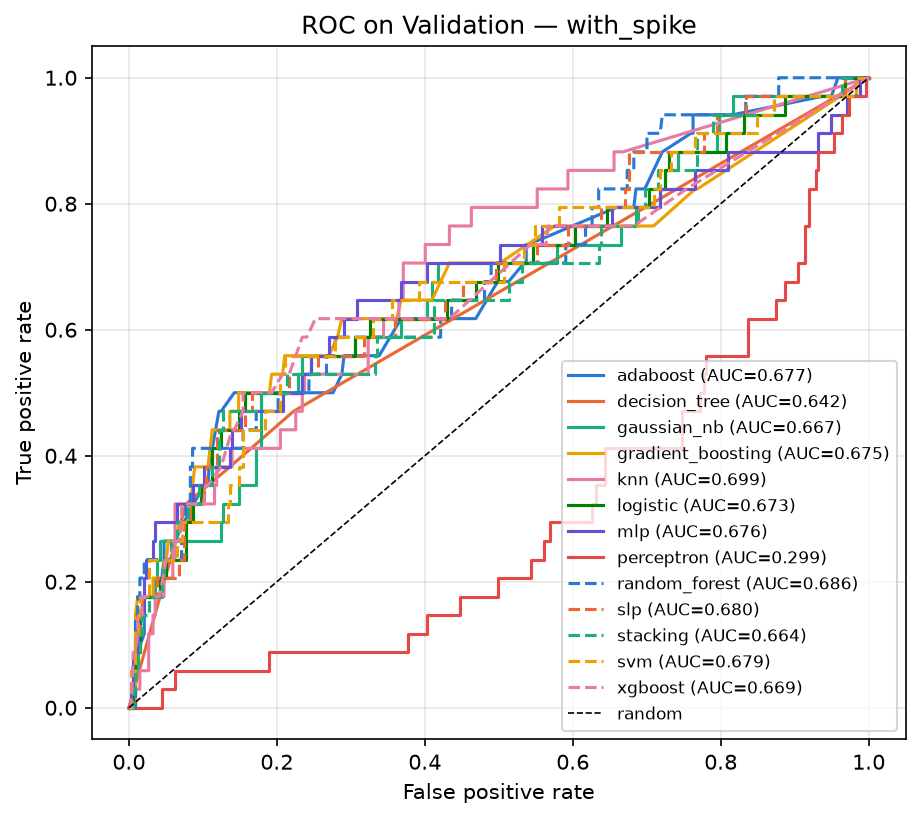

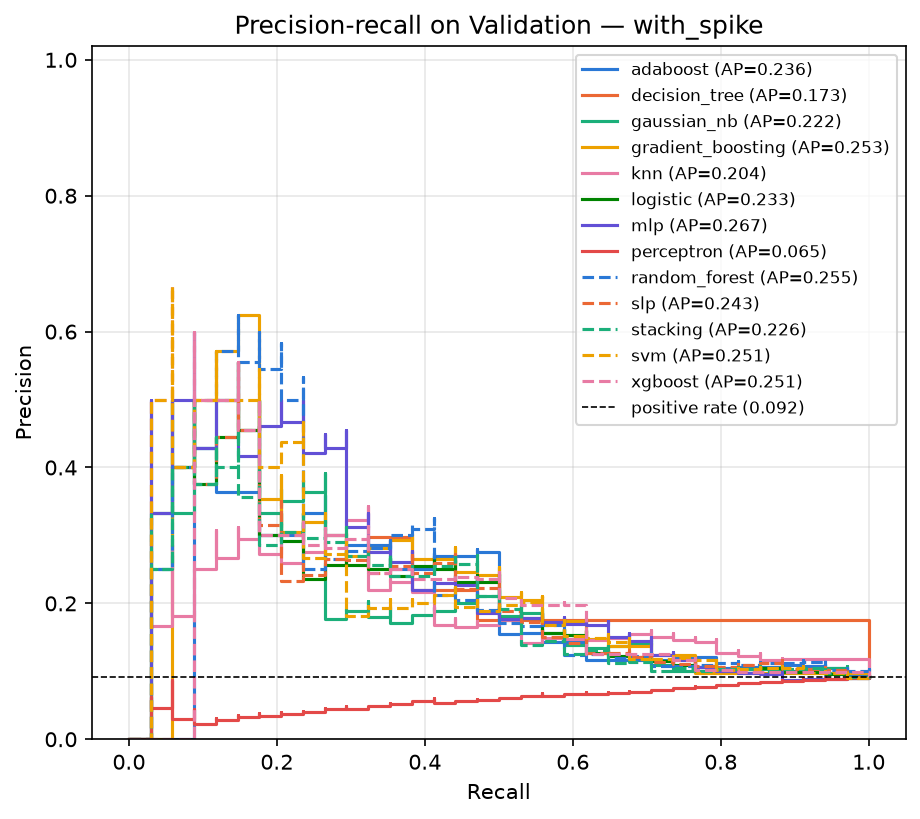

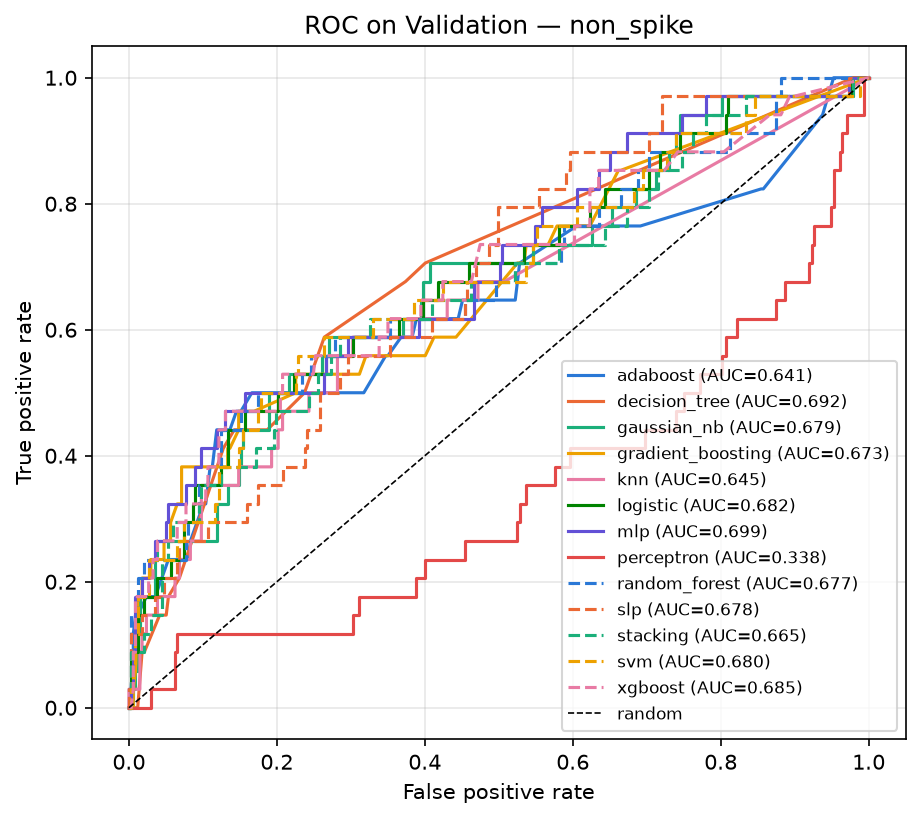

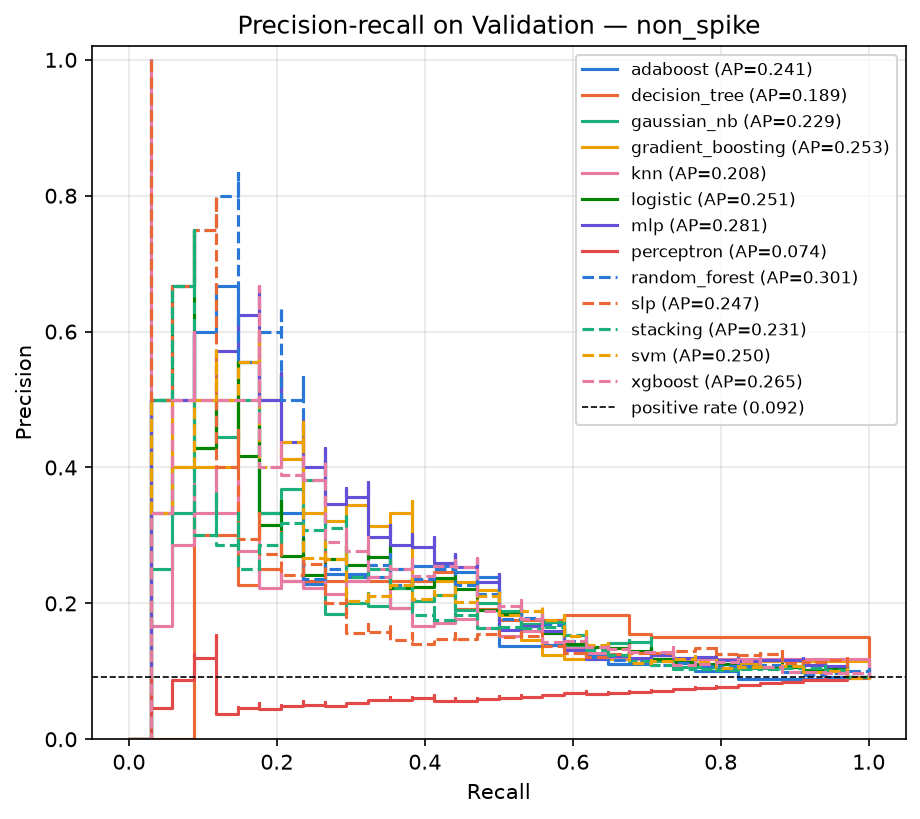

In [6]:
for variant in VARIANTS:
    show_image(FIGURE_ROOT / variant / "roc_overlay.png", width=640)
    show_image(FIGURE_ROOT / variant / "pr_overlay.png", width=640)

## 6. Confusion matrix

แต่ละกล่องคือหนึ่งโมเดล ช่องขวาล่าง (TP) คือวันผันผวนสูงที่จับได้ จากทั้งหมด 34 วัน

สังเกตว่าหลายโมเดลทำนาย positive น้อยมาก จึงจับได้เพียง 5 ถึง 11 วัน สาเหตุคือโมเดลเรียนจาก Train ที่มี positive 25% แต่ feature ของ Validation อยู่ในช่วงสงบ ความน่าจะเป็นที่โมเดลให้จึงไม่ค่อยข้าม 0.5

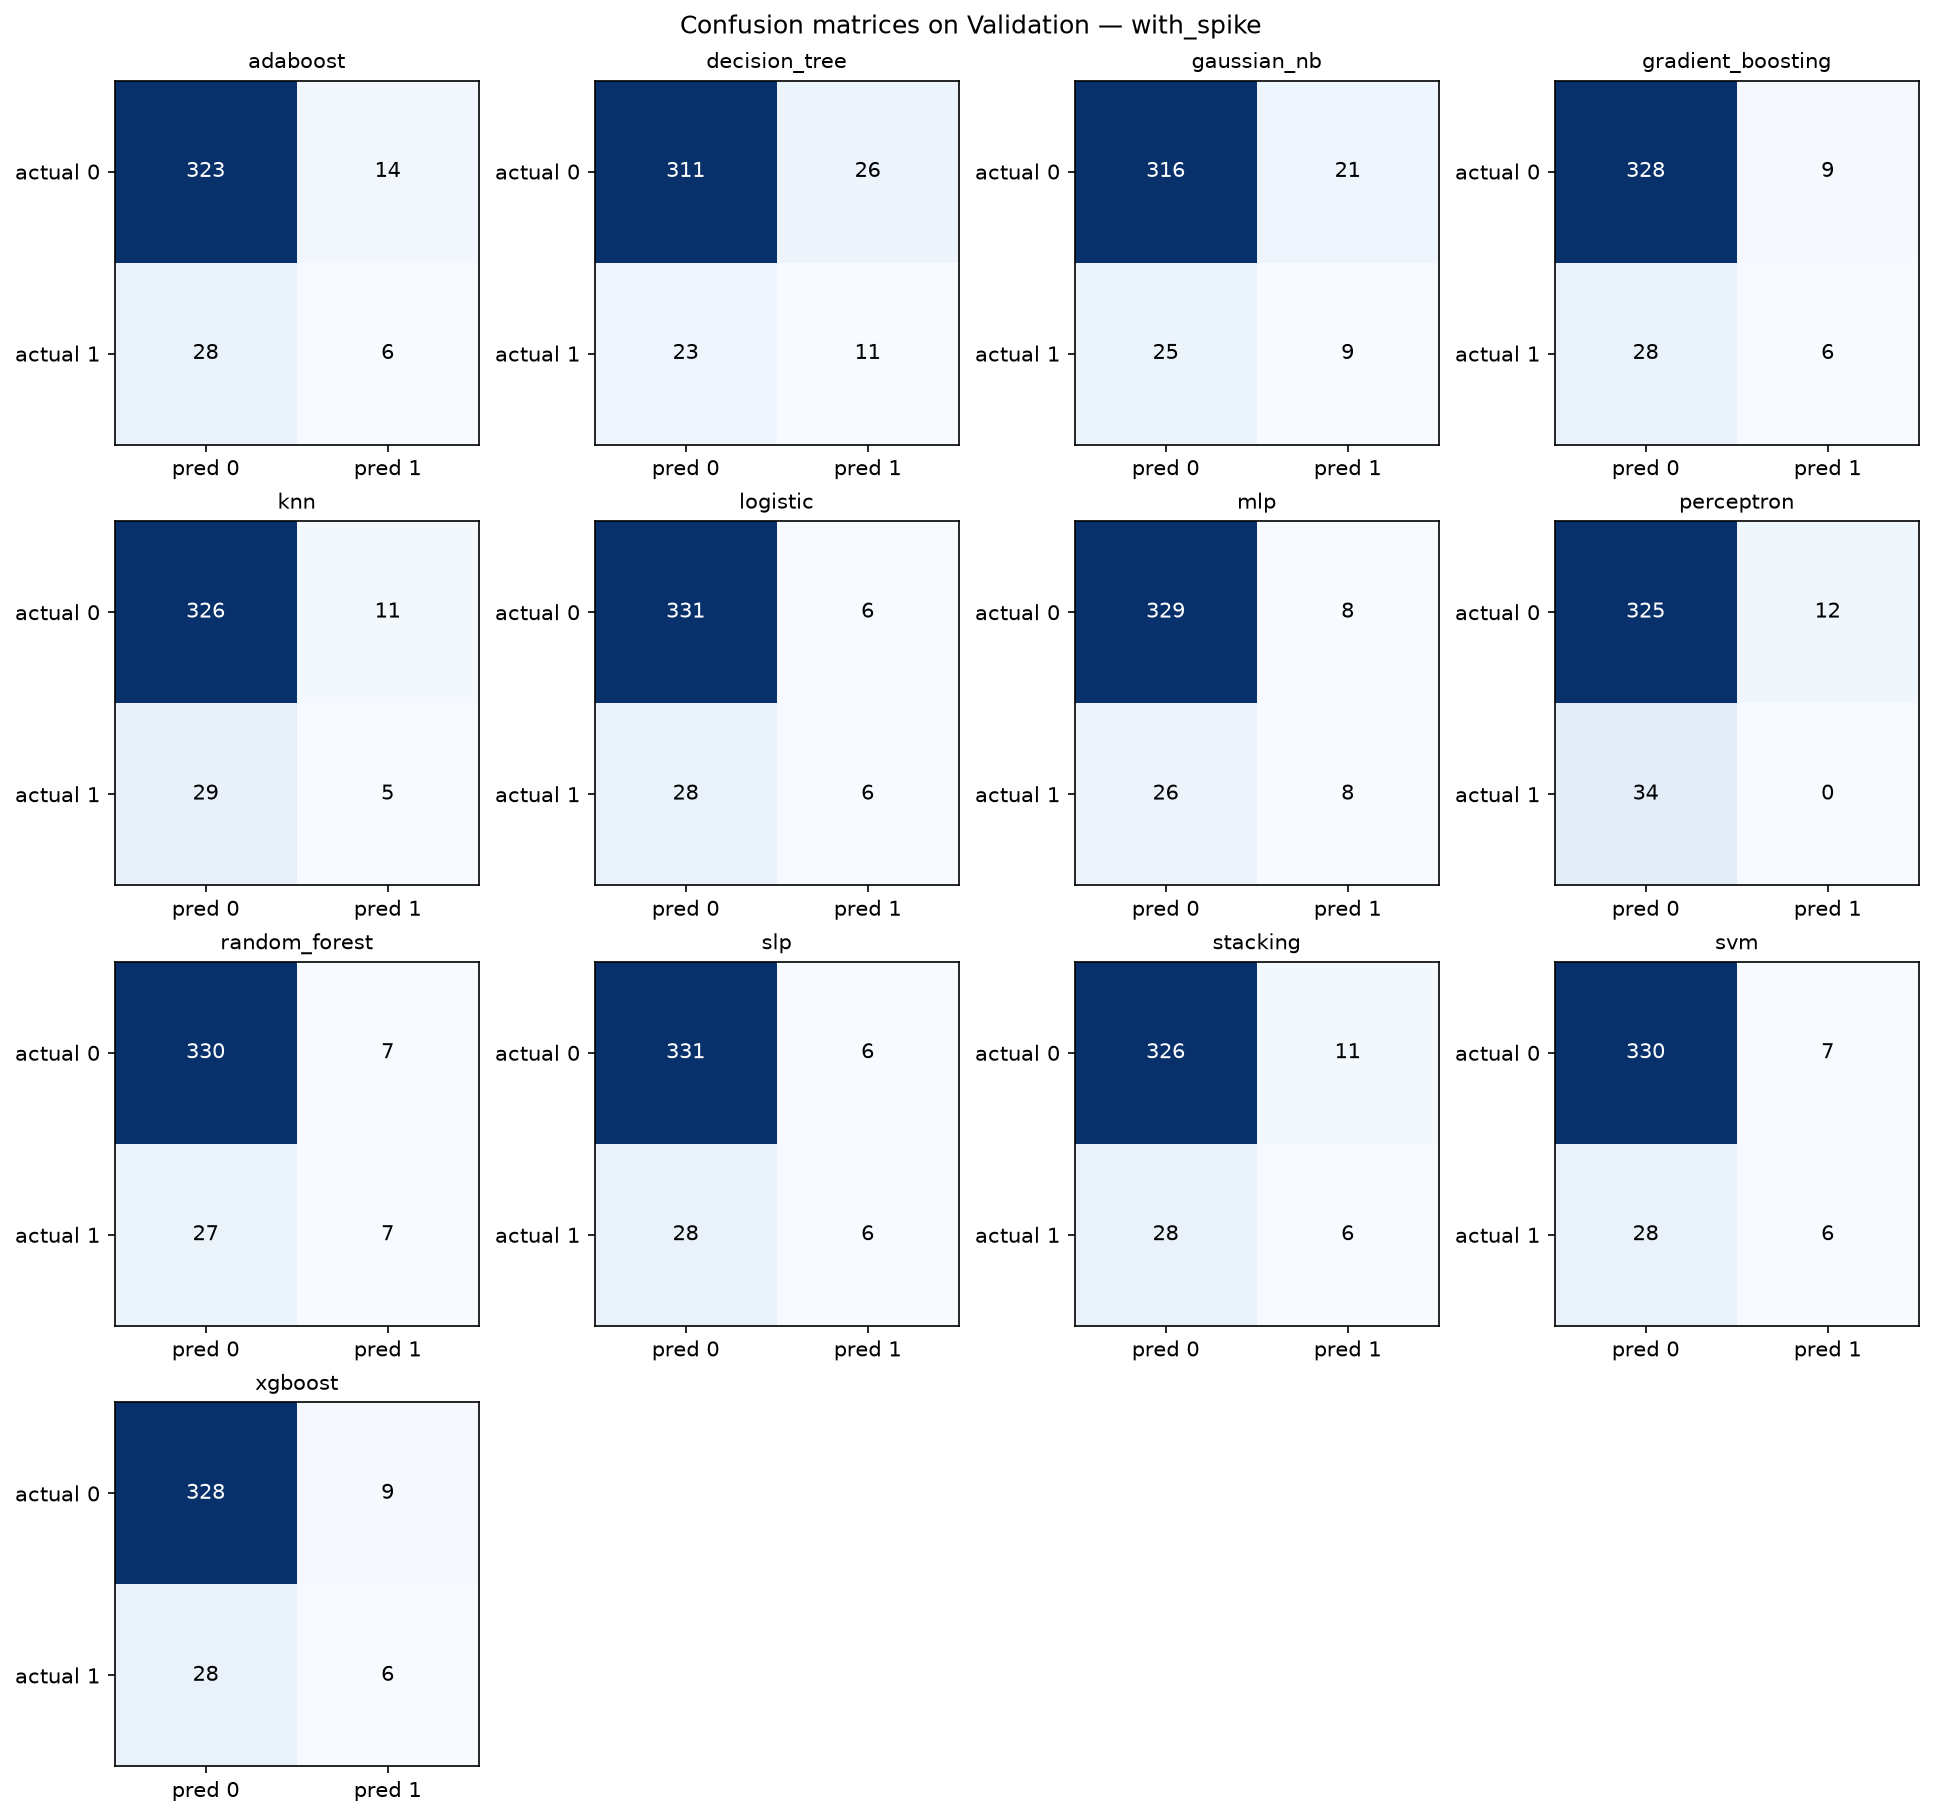

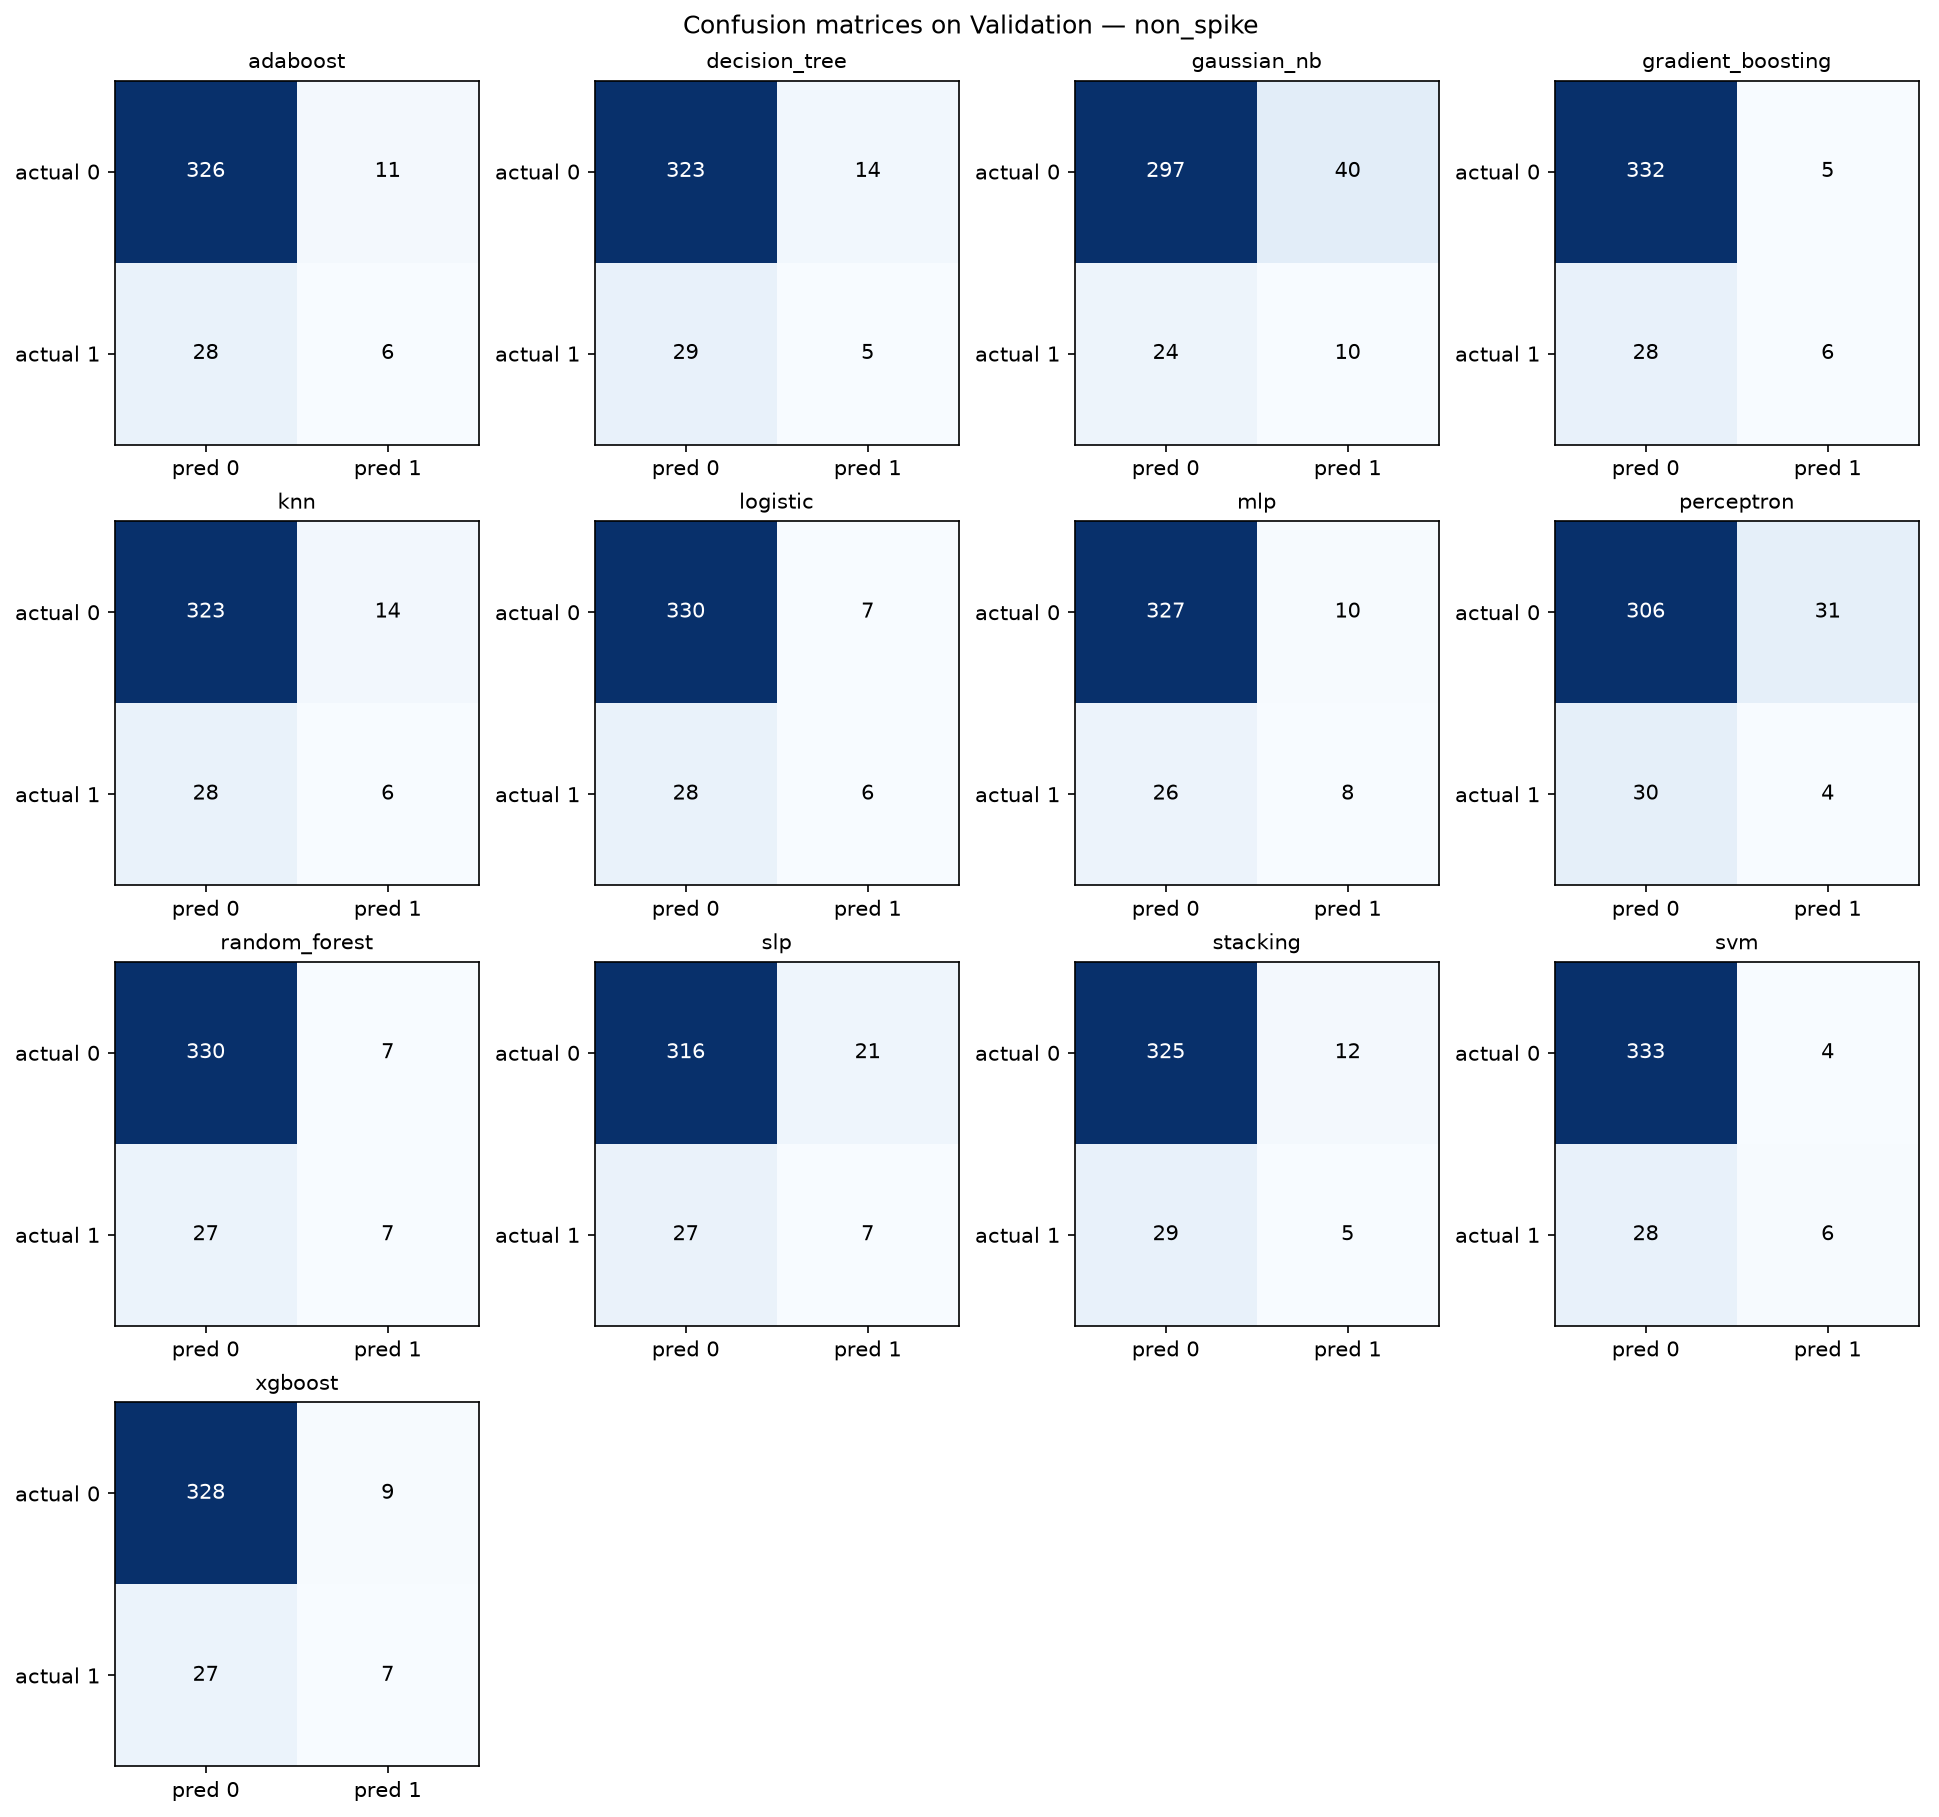

In [7]:
for variant in VARIANTS:
    show_image(FIGURE_ROOT / variant / "confusion_matrices.png", width=1000)

## 7. Performance curve

loss ระหว่างเทรนของโมเดลที่เรียนแบบวนรอบ ใช้ดูว่าโมเดลเรียนจนนิ่งหรือยัง

- เส้นที่ลดลงแล้วราบ = ลู่เข้าแล้ว
- `perceptron` แกว่งไม่ลู่เข้า เพราะข้อมูลแยกด้วยเส้นตรงไม่ได้ ซึ่งเป็นพฤติกรรมปกติของอัลกอริทึมนี้ และอธิบายคะแนนที่แย่ของมัน
- `knn`, `decision_tree`, `gaussian_nb`, `random_forest`, `stacking` ไม่มีกราฟ เพราะไม่ได้เทรนด้วยการลด loss ทีละรอบ

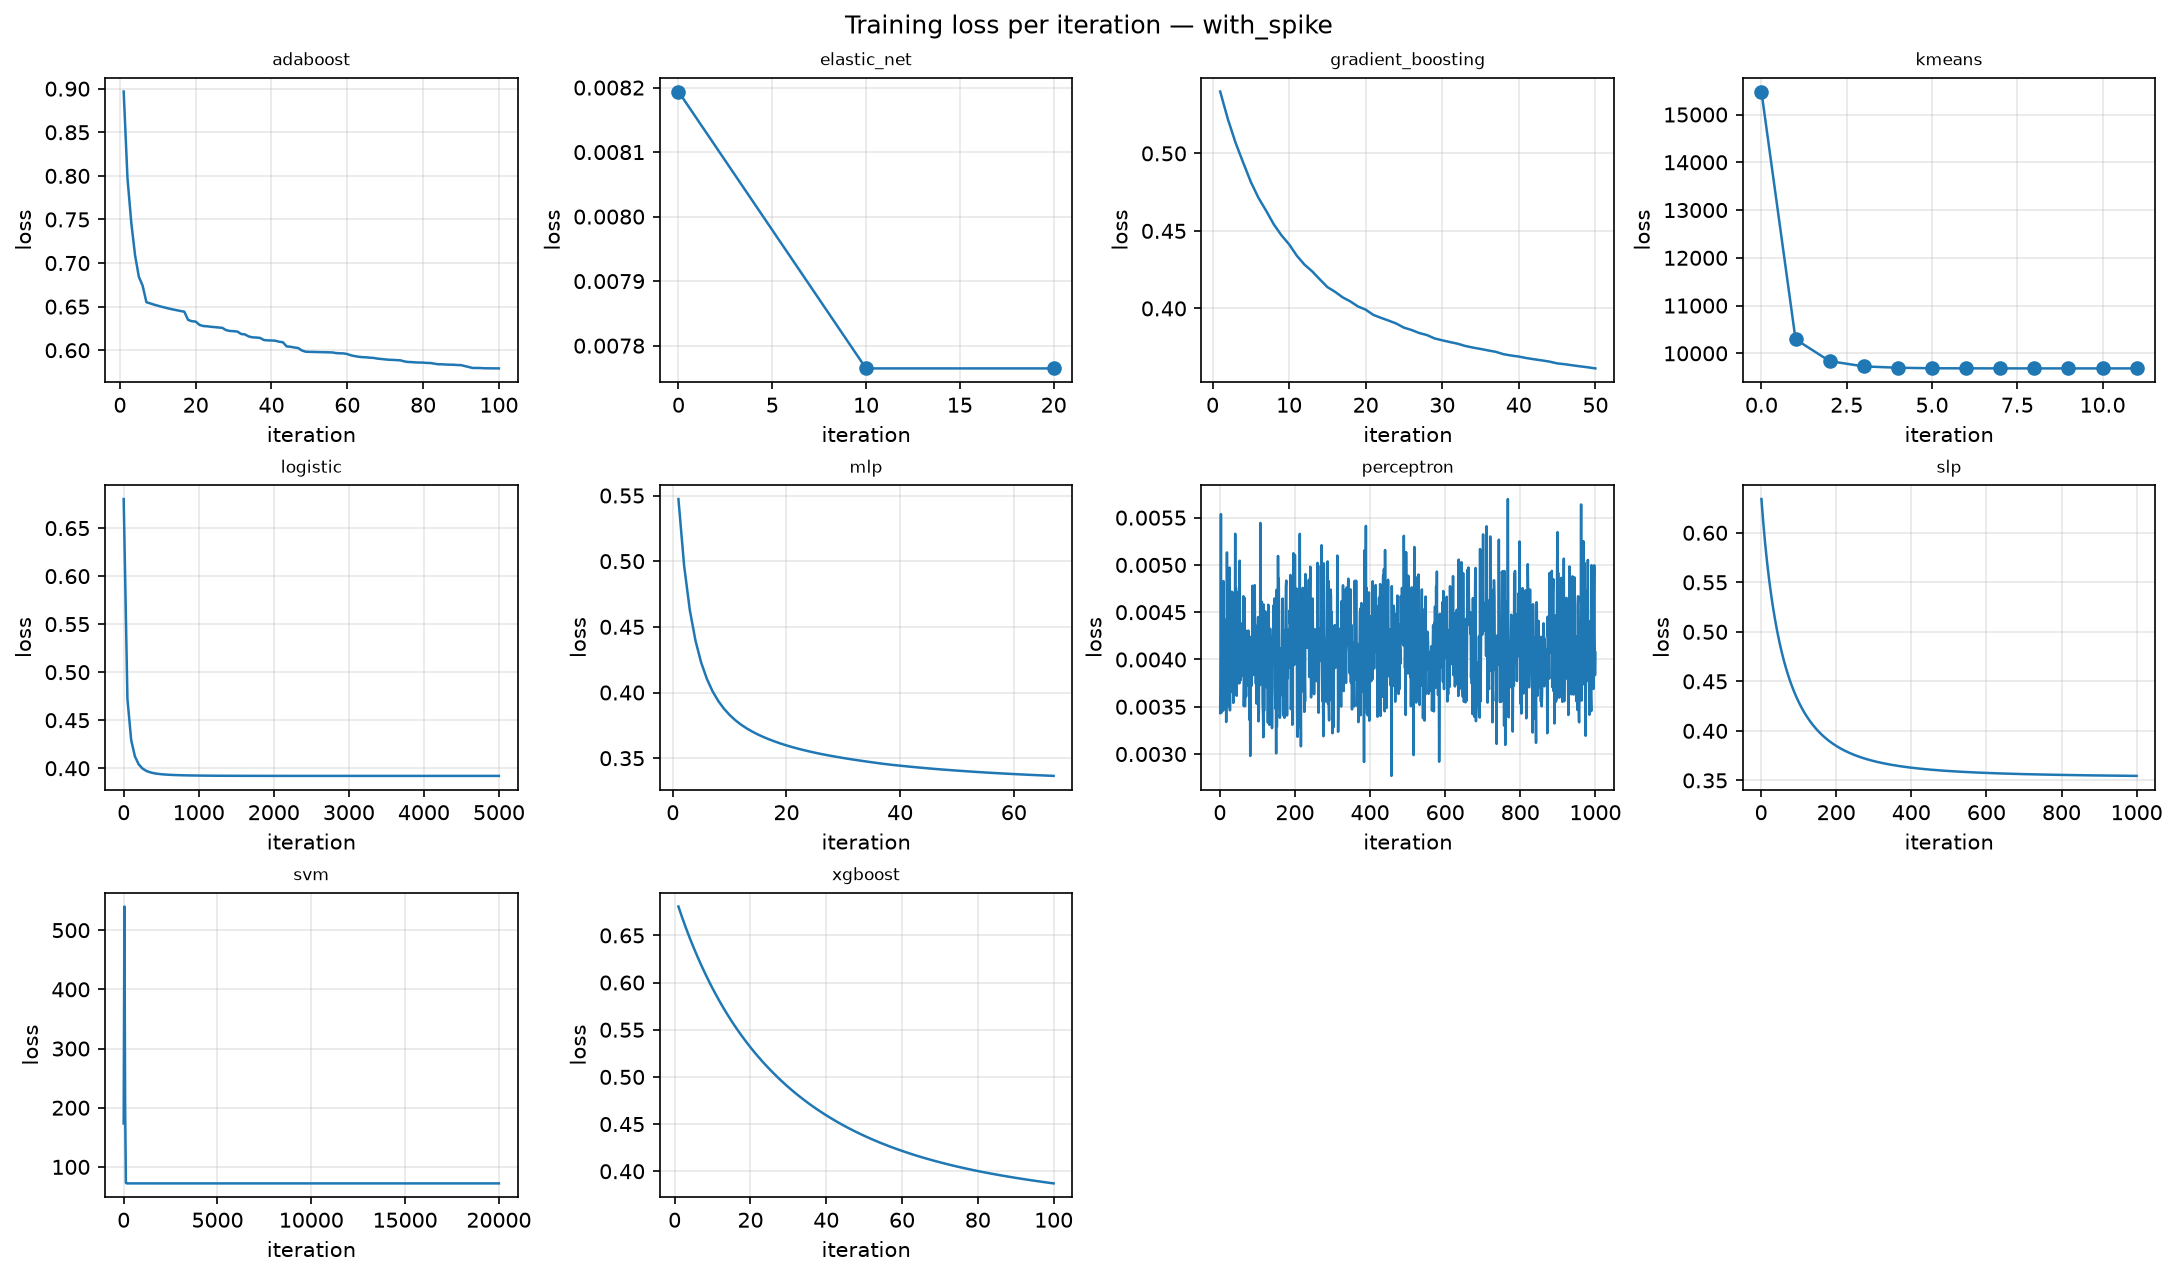

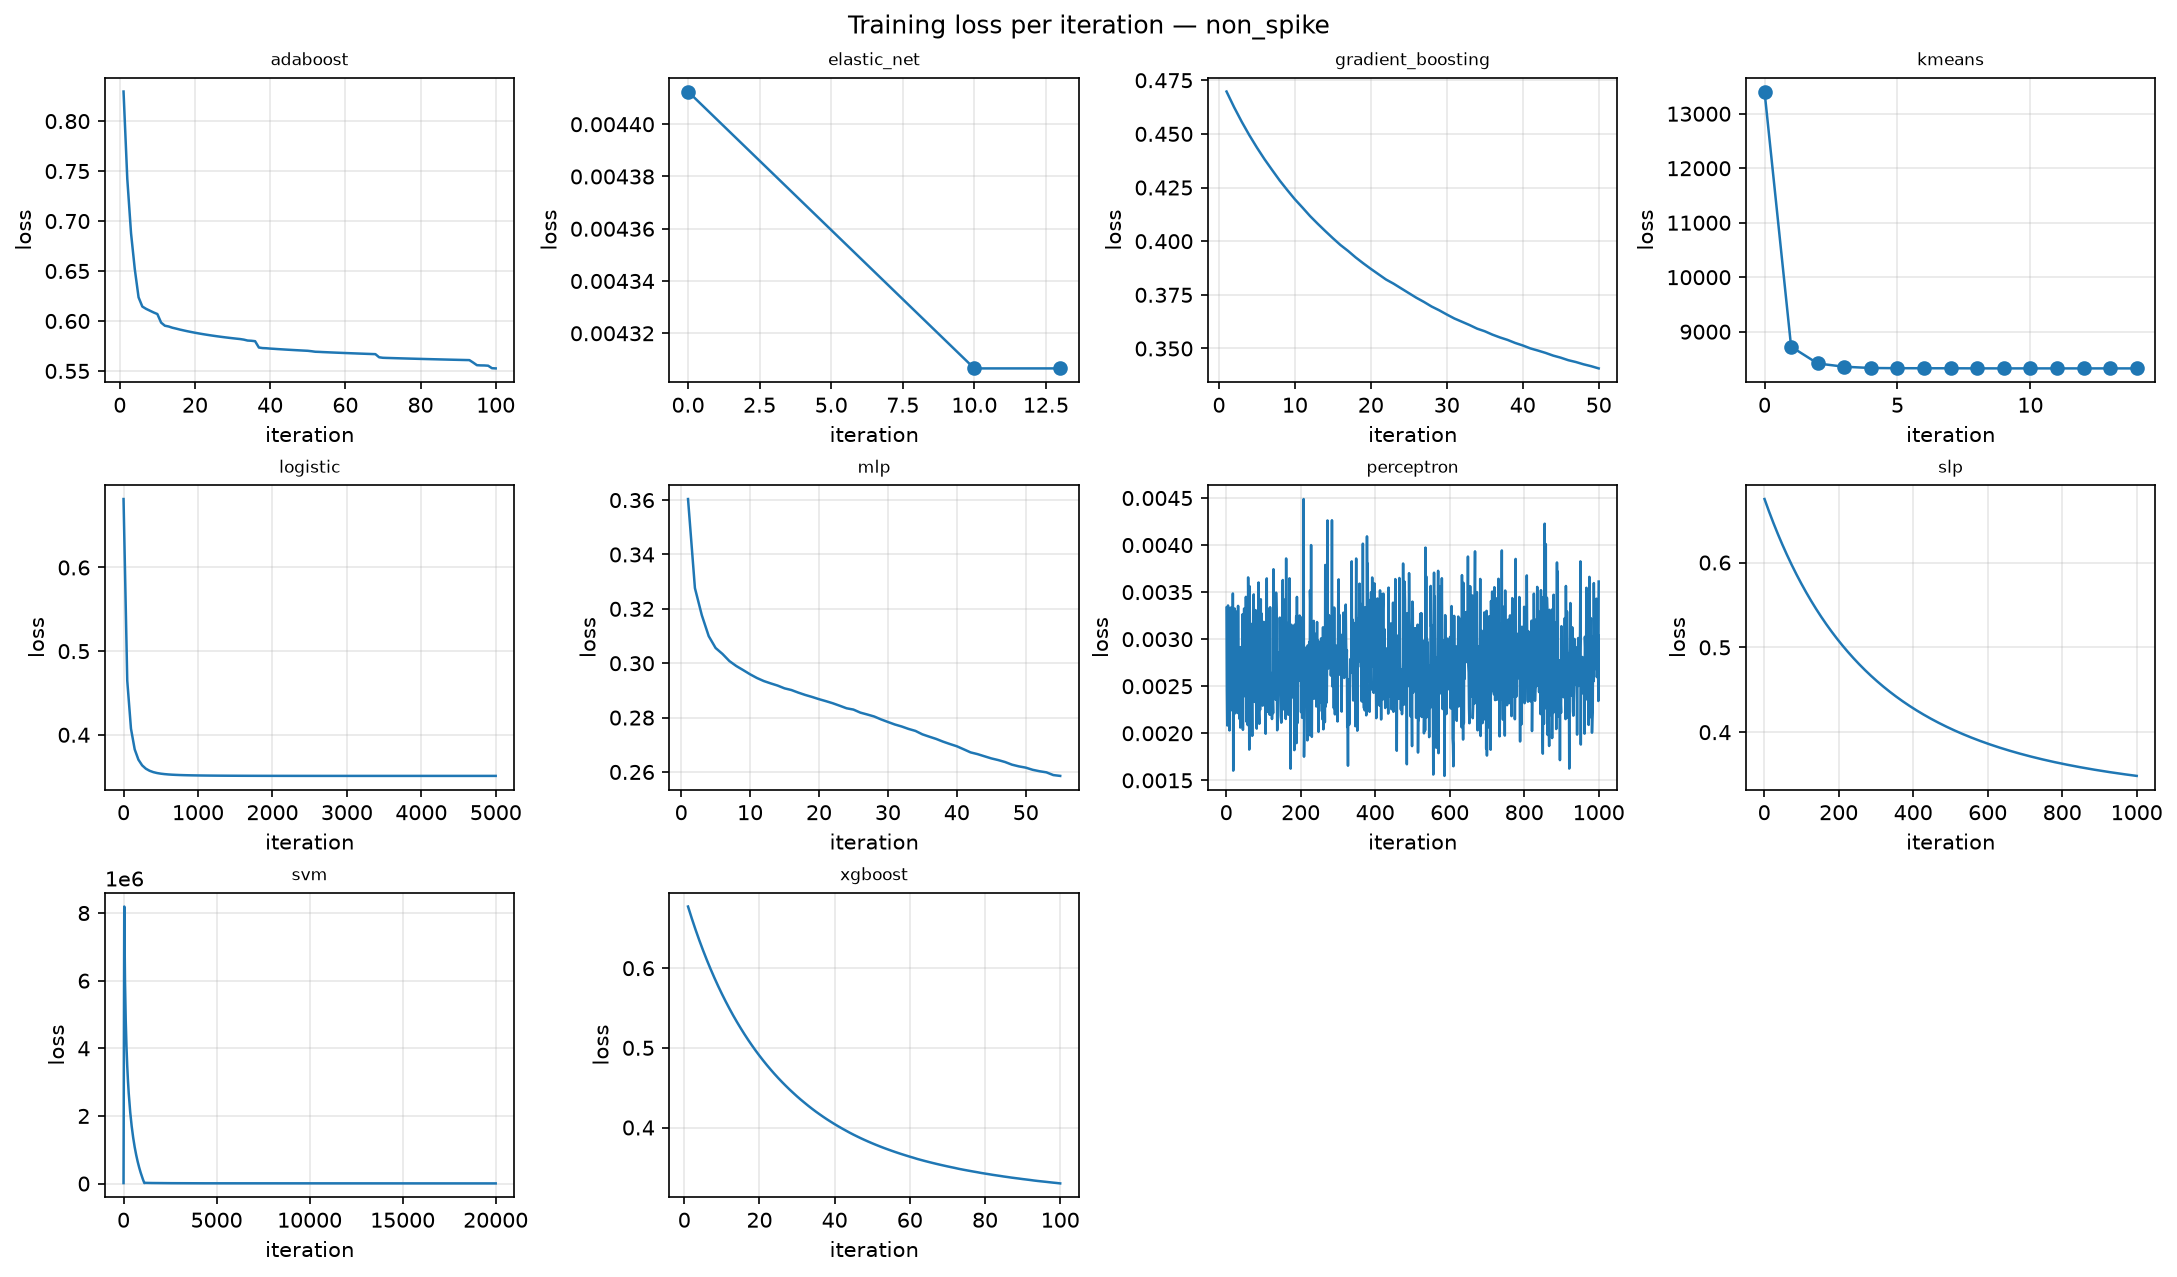

In [8]:
for variant in VARIANTS:
    show_image(FIGURE_ROOT / variant / "performance_curves.png", width=1000)

## 8. AdaBoost: โมเดลนอกห้องเรียน

AdaBoost สร้างโมเดลอ่อน (ที่นี่คือ decision stump = ต้นไม้ที่ถามคำถามเดียว) ต่อกันทีละตัว โดย **ตัวถัดไปตั้งใจแก้จุดที่ตัวก่อนหน้าทำผิด**

ขั้นตอนของแต่ละรอบ m (อัลกอริทึม SAMME):

1. เทรน stump บนข้อมูลที่แต่ละแถวมีน้ำหนัก เริ่มต้นทุกแถวหนักเท่ากัน
2. คำนวณ error แบบถ่วงน้ำหนัก ε_m
3. ให้ stump มีสิทธิ์ออกเสียง α_m = learning_rate · ln((1 − ε_m) / ε_m) ยิ่งผิดน้อยยิ่งมีเสียงมาก (สูตรของ SAMME ซึ่งเป็นสองเท่าของสูตรในตำราที่มี ½ นำหน้า การตั้งค่าที่ชนะใช้ learning_rate = 0.5)
4. เพิ่มน้ำหนักให้แถวที่ทำนายผิด เพื่อให้ stump ตัวถัดไปสนใจแถวเหล่านั้น

คำตอบสุดท้ายคือผลโหวตถ่วงน้ำหนักของ stump ทั้งหมด

**ทำไมเลือกตัวนี้:** AdaBoost ลด exponential loss ซึ่งไวต่อจุดที่ทำนายผิดหนัก ๆ จึงน่าสนใจเป็นพิเศษกับคำถามว่าช่วง spike รบกวนการเรียนรู้หรือไม่

กราฟถัดไปแสดง ε_m และ α_m ของ stump ทั้ง 100 ตัว

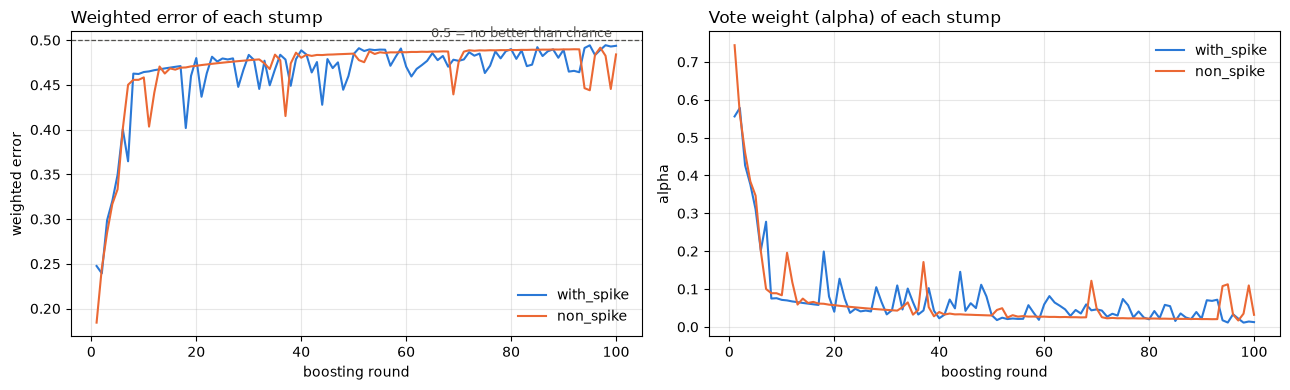

In [9]:
from src.ml.core.persist import load_npz

figure, panels = plt.subplots(1, 2, figsize=(13, 4))
for variant, color in zip(VARIANTS, ["#2a78d6", "#eb6834"]):
    arrays, _ = load_npz(read_run(OUTPUT_ROOT, variant, "adaboost").directory / "model.npz")
    rounds = np.arange(1, len(arrays["estimator_errors"]) + 1)
    panels[0].plot(rounds, arrays["estimator_errors"], color=color, linewidth=1.5, label=variant)
    panels[1].plot(rounds, arrays["estimator_weights"], color=color, linewidth=1.5, label=variant)
panels[0].axhline(0.5, color="#52514e", linestyle="--", linewidth=0.9)
panels[0].text(100, 0.5, "0.5 = no better than chance ", ha="right", va="bottom", fontsize=9, color="#52514e")
panels[0].set_title("Weighted error of each stump", loc="left")
panels[0].set_ylabel("weighted error")
panels[1].set_title("Vote weight (alpha) of each stump", loc="left")
panels[1].set_ylabel("alpha")
for axes in panels:
    axes.set_xlabel("boosting round")
    axes.grid(alpha=0.3)
    axes.legend(frameon=False)
figure.tight_layout()
plt.show()

**อ่านกราฟ:** stump รอบแรก ๆ มี error ต่ำและได้เสียงโหวตมาก รอบหลัง ๆ error ขยับเข้าใกล้ 0.5 (เส้นประ) เพราะแถวที่เหลือให้แก้คือแถวที่ยากจริง ๆ เสียงโหวตจึงเล็กลงเรื่อย ๆ

## 9. PCA กับ Random Forest และ SVM

โจทย์กำหนดให้ลอง dimensionality reduction กับสองโมเดลนี้ **PCA** หมุนแกนข้อมูลแล้วเก็บเฉพาะทิศทางที่ข้อมูลกระจายตัวมากที่สุด เช่น ย่อ feature 8 ตัวเหลือ 4 ตัว

PCA ถูก fit บน Train เท่านั้น (หลัง standardize) แล้วนำไปแปลง Validation

ตารางถัดไปแสดง AP ที่ดีที่สุดของแต่ละจำนวน component `none` คือไม่ใช้ PCA

In [10]:
pca_rows = []
for variant in VARIANTS:
    for name in ("random_forest", "svm"):
        run = read_run(OUTPUT_ROOT, variant, name)
        for item in json.loads((run.directory / "search_results.json").read_text(encoding="utf-8")):
            if item.get("status", "valid") != "valid":
                continue
            pca_rows.append({"variant": variant, "model": name,
                             "pca_components": item["pca_components"] or "none",
                             "average_precision": item["metrics"]["average_precision"]["value"]})
pca_table = (pd.DataFrame(pca_rows).groupby(["variant", "model", "pca_components"])["average_precision"].max()
             .unstack("pca_components")[["none", 2, 4, 6]])
display(pca_table.round(4))
selected = pd.DataFrame([{"variant": variant, "model": name,
                          "selected pca_components": read_run(OUTPUT_ROOT, variant, name).config["pca_components"] or "none"}
                         for variant in VARIANTS for name in ("random_forest", "svm")])
display(selected)

pca_components              none       2       4       6
variant    model                                        
non_spike  random_forest  0.3010  0.1972  0.2164  0.2038
           svm            0.2172  0.2485  0.2501  0.2452
with_spike random_forest  0.2548  0.2045  0.2235  0.2172
           svm            0.2151  0.2458  0.2514  0.2475

,variant,model,selected pca_components
0,with_spike,random_forest,none
1,with_spike,svm,4
2,non_spike,random_forest,none
3,non_spike,svm,4


## 10. Clustering: k-Means และ Agglomerative

Clustering เป็น **unsupervised learning**: โมเดลไม่เห็น label ตอนเทรน มันแค่จัดวันที่มี feature คล้ายกันไว้กลุ่มเดียวกัน

- **k-Means**: เลือกจุดศูนย์กลาง k จุด แล้วสลับระหว่าง "จัดแต่ละวันเข้าศูนย์กลางที่ใกล้สุด" กับ "ย้ายศูนย์กลางไปที่ค่าเฉลี่ยของกลุ่ม" จนนิ่ง
- **Agglomerative**: เริ่มจากทุกวันเป็นกลุ่มของตัวเอง แล้วรวมสองกลุ่มที่ใกล้กันที่สุดซ้ำ ๆ จนเหลือ k กลุ่ม วิธีนี้ไม่มีขั้นตอนทำนายข้อมูลใหม่โดยธรรมชาติ เราจึงจัดวันใน Validation เข้ากลุ่มที่จุดศูนย์กลางใกล้ที่สุด

**Silhouette** วัดว่ากลุ่มแยกจากกันชัดแค่ไหน ค่าอยู่ระหว่าง −1 ถึง 1 ยิ่งสูงยิ่งแยกชัด

ตาราง crosstab ถัดไปตอบคำถามที่น่าสนใจกว่า: กลุ่มที่ได้ (ซึ่งไม่เคยเห็น label) ตรงกับวันผันผวนสูงแค่ไหน

In [11]:
for variant in VARIANTS:
    show_markdown(REPORT_ROOT / variant / "leaderboard_clustering.md")
    for name in ("kmeans", "agglomerative"):
        run = read_run(OUTPUT_ROOT, variant, name)
        cross = pd.crosstab(pd.Series(run.prediction.astype(int), name=f"{name} cluster"),
                            pd.Series(run.target.astype(int), name="high volatility (actual)"), margins=True)
        cross["positive rate"] = (cross[1] / cross["All"]).round(3)
        display(cross)

### Validation clustering metrics — with_spike

| model | variant | k | silhouette | inertia | cluster_sizes |
| --- | --- | --- | --- | --- | --- |
| agglomerative | with_spike | 2 | 0.3602 | 1070.4207 | {"0": 293, "1": 78} |
| kmeans | with_spike | 2 | 0.3666 | 1075.1372 | {"0": 73, "1": 298} |

> silhouette/inertia คำนวณบน Validation ไม่มีช่วงความเชื่อมั่น


high volatility (actual),0,1,All,positive rate
kmeans cluster,,,,
0,57,16,73,0.219
1,280,18,298,0.060
All,337,34,371,0.092


high volatility (actual),0,1,All,positive rate
agglomerative cluster,,,,
0,275,18,293,0.061
1,62,16,78,0.205
All,337,34,371,0.092


### Validation clustering metrics — non_spike

| model | variant | k | silhouette | inertia | cluster_sizes |
| --- | --- | --- | --- | --- | --- |
| agglomerative | non_spike | 2 | 0.4642 | 1844.8884 | {"0": 359, "1": 12} |
| kmeans | non_spike | 2 | 0.3298 | 1448.9259 | {"0": 267, "1": 104} |

> silhouette/inertia คำนวณบน Validation ไม่มีช่วงความเชื่อมั่น


high volatility (actual),0,1,All,positive rate
kmeans cluster,,,,
0,251,16,267,0.060
1,86,18,104,0.173
All,337,34,371,0.092


high volatility (actual),0,1,All,positive rate
agglomerative cluster,,,,
0,331,28,359,0.078
1,6,6,12,0.500
All,337,34,371,0.092


**อ่าน crosstab:** ถ้ากลุ่มหนึ่งมี `positive rate` สูงกว่าอีกกลุ่มชัดเจน แปลว่า feature เพียงอย่างเดียวก็แยกสภาพตลาดได้ระดับหนึ่งโดยไม่ต้องมี label เทียบกับ positive rate รวม 0.092

## 11. Save → load → ทำนายซ้ำ

เหมือนเล่ม 03: โหลด `model.npz` และ `preprocessor.npz` ของทุก run ขึ้นมาใหม่ ทำนาย Validation อีกรอบ แล้วเทียบกับค่าที่บันทึกไว้ ครอบคลุม classifier 13 ตัวและ clustering 2 ตัว ทั้งสอง variant รวม 30 run

In [12]:
checks = []
for variant in VARIANTS:
    validation = data[variant].validation
    for run in read_runs(OUTPUT_ROOT, variant):
        if run.task == "regression":
            continue
        model, transform = load_model(run.directory)
        _, prediction, _ = evaluate(model, transform(validation.X), validation.y_regression,
                                    validation.y_classification, run.task)
        stored = json.loads((run.directory / "load_verification.json").read_text(encoding="utf-8"))
        checks.append({"variant": variant, "task": run.task, "model": run.name, "stored_passed": stored["passed"],
                       "reproduced_here": bool(np.array_equal(prediction, run.prediction))})
checks = pd.DataFrame(checks)
with pd.option_context("display.max_rows", 40):
    display(checks)
print(len(checks), "runs checked; all reproduced:", bool(checks["reproduced_here"].all()))
assert checks["stored_passed"].all() and checks["reproduced_here"].all()

,variant,task,model,stored_passed,reproduced_here
0,with_spike,classification,adaboost,True,True
1,with_spike,clustering,agglomerative,True,True
2,with_spike,classification,decision_tree,True,True
3,with_spike,classification,gaussian_nb,True,True
4,with_spike,classification,gradient_boosting,True,True
5,with_spike,clustering,kmeans,True,True
6,with_spike,classification,knn,True,True
7,with_spike,classification,logistic,True,True
8,with_spike,classification,mlp,True,True
9,with_spike,classification,perceptron,True,True


30 runs checked; all reproduced: True


## 12. เทียบกับ library (parity demo)

โมเดลของเรา **โหลดจากไฟล์** ส่วนโมเดลของ scikit-learn ถูก fit ตรงนี้บน Train ชุดเดียวกันด้วยการตั้งค่าเดียวกัน แล้วเทียบคำทำนายบน Validation

เราเลือกสามตัวที่ต่างกันทางวิธีคิด: `adaboost` (โมเดลนอกห้องเรียน), `knn` (อิงระยะทาง) และ `gaussian_nb` (อิงความน่าจะเป็น)

หมายเหตุ: โมเดลที่มีการสุ่มต้องใช้ตัวสุ่มชนิดเดียวกับ scikit-learn (`numpy.random.RandomState`) จึงจะได้ผลตรงกัน ผลเทียบครบทั้ง 19 โมเดลอยู่ใน test ของแต่ละโมเดลใต้ `tests/ml/`

In [13]:
PARITY_MODELS = ['adaboost', 'knn', 'gaussian_nb']


def parity_demo(name, variant="with_spike"):
    """Scratch model reloaded from disk vs the library reference fitted on the same inputs."""
    data = load(variant)
    run = read_run(OUTPUT_ROOT, variant, name)
    scratch, transform = load_model(run.directory)
    train_X, validation_X = transform(data.train.X), transform(data.validation.X)
    y = data.train.y_regression if run.task == "regression" else data.train.y_classification
    reference = scratch.reference().fit(train_X, y)
    result = assert_parity(scratch, reference, validation_X, task=run.task)
    gap = np.abs(np.asarray(scratch.predict(validation_X), dtype=float)
                 - np.asarray(reference.predict(validation_X), dtype=float)).max()
    return {"model": name, "reference": type(reference).__name__, "rows": result["n_samples"],
            "max_abs_diff": float(gap), "rtol": result["rtol"], "passed": result["passed"]}


parity_rows = [parity_demo(name) for name in PARITY_MODELS]

display(pd.DataFrame(parity_rows))

,model,reference,rows,max_abs_diff,rtol,passed
0,adaboost,AdaBoostClassifier,371,0.0,0.00001,True
1,knn,KNeighborsClassifier,371,0.0,0.00001,True
2,gaussian_nb,GaussianNB,371,0.0,0.00001,True


## 13. ฟีเจอร์ไหนสำคัญ

**วิธีวัด (block-permutation importance):** สลับลำดับค่าของ feature หนึ่งตัวบน Validation เป็นก้อน 20 วัน แล้วดูว่า AP ลดลงเท่าไร ทำซ้ำ 30 รอบ

- สีเข้ม = สลับแล้ว AP ลดลงมาก = โมเดลพึ่ง feature นั้นมาก
- ค่าติดลบ = สลับแล้ว AP ดีขึ้น = feature นั้นไม่ช่วยบน Validation ชุดนี้
- feature ที่สัมพันธ์กันจะแบ่งความสำคัญกัน และ AP ตั้งอยู่บนวัน positive 34 วัน จึงต้องอ่านคู่กับ `std` เสมอ

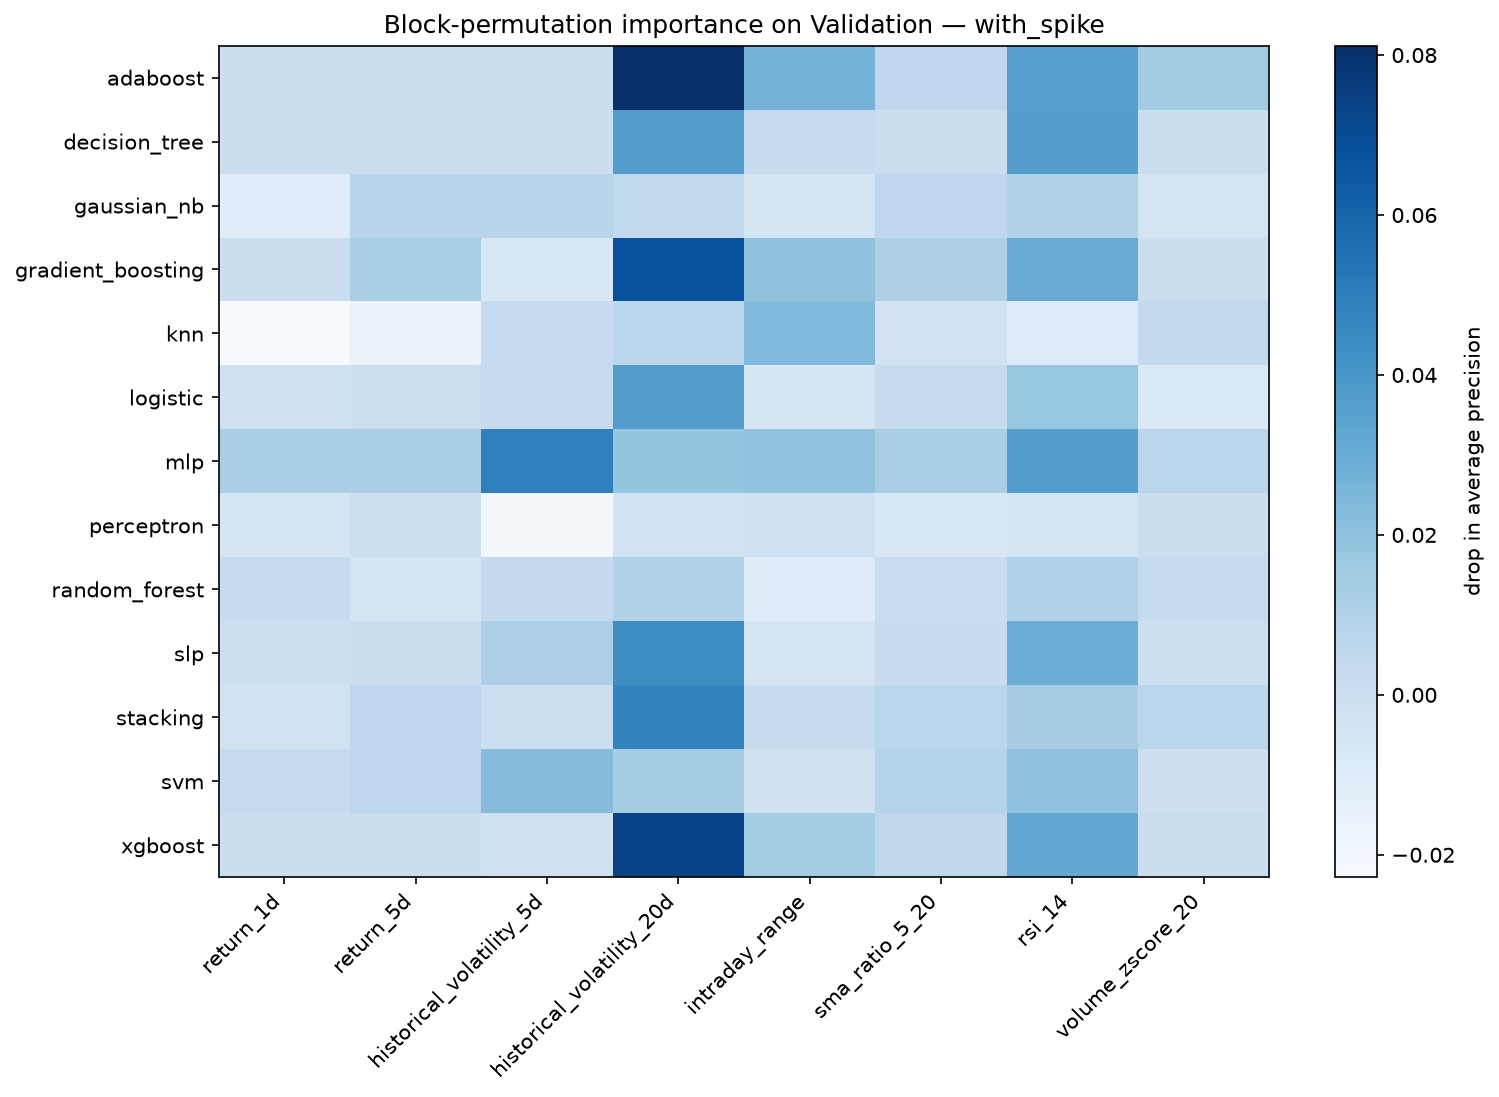

with_spike


,most important,second,third
model,,,
adaboost,historical_volatility_20d (+0.081 ± 0.056),rsi_14 (+0.036 ± 0.019),intraday_range (+0.027 ± 0.027)
decision_tree,historical_volatility_20d (+0.037 ± 0.050),rsi_14 (+0.036 ± 0.021),intraday_range (+0.002 ± 0.008)
gaussian_nb,rsi_14 (+0.010 ± 0.020),return_5d (+0.008 ± 0.010),historical_volatility_5d (+0.007 ± 0.011)
gradient_boosting,historical_volatility_20d (+0.068 ± 0.059),rsi_14 (+0.030 ± 0.019),intraday_range (+0.020 ± 0.021)
knn,intraday_range (+0.023 ± 0.020),historical_volatility_20d (+0.006 ± 0.029),volume_zscore_20 (+0.004 ± 0.014)
logistic,historical_volatility_20d (+0.037 ± 0.050),rsi_14 (+0.018 ± 0.022),sma_ratio_5_20 (+0.003 ± 0.011)
mlp,historical_volatility_5d (+0.049 ± 0.040),rsi_14 (+0.036 ± 0.023),intraday_range (+0.019 ± 0.032)
perceptron,volume_zscore_20 (+0.000 ± 0.002),return_5d (-0.000 ± 0.002),intraday_range (-0.001 ± 0.002)
random_forest,rsi_14 (+0.010 ± 0.016),historical_volatility_20d (+0.010 ± 0.033),historical_volatility_5d (+0.003 ± 0.026)


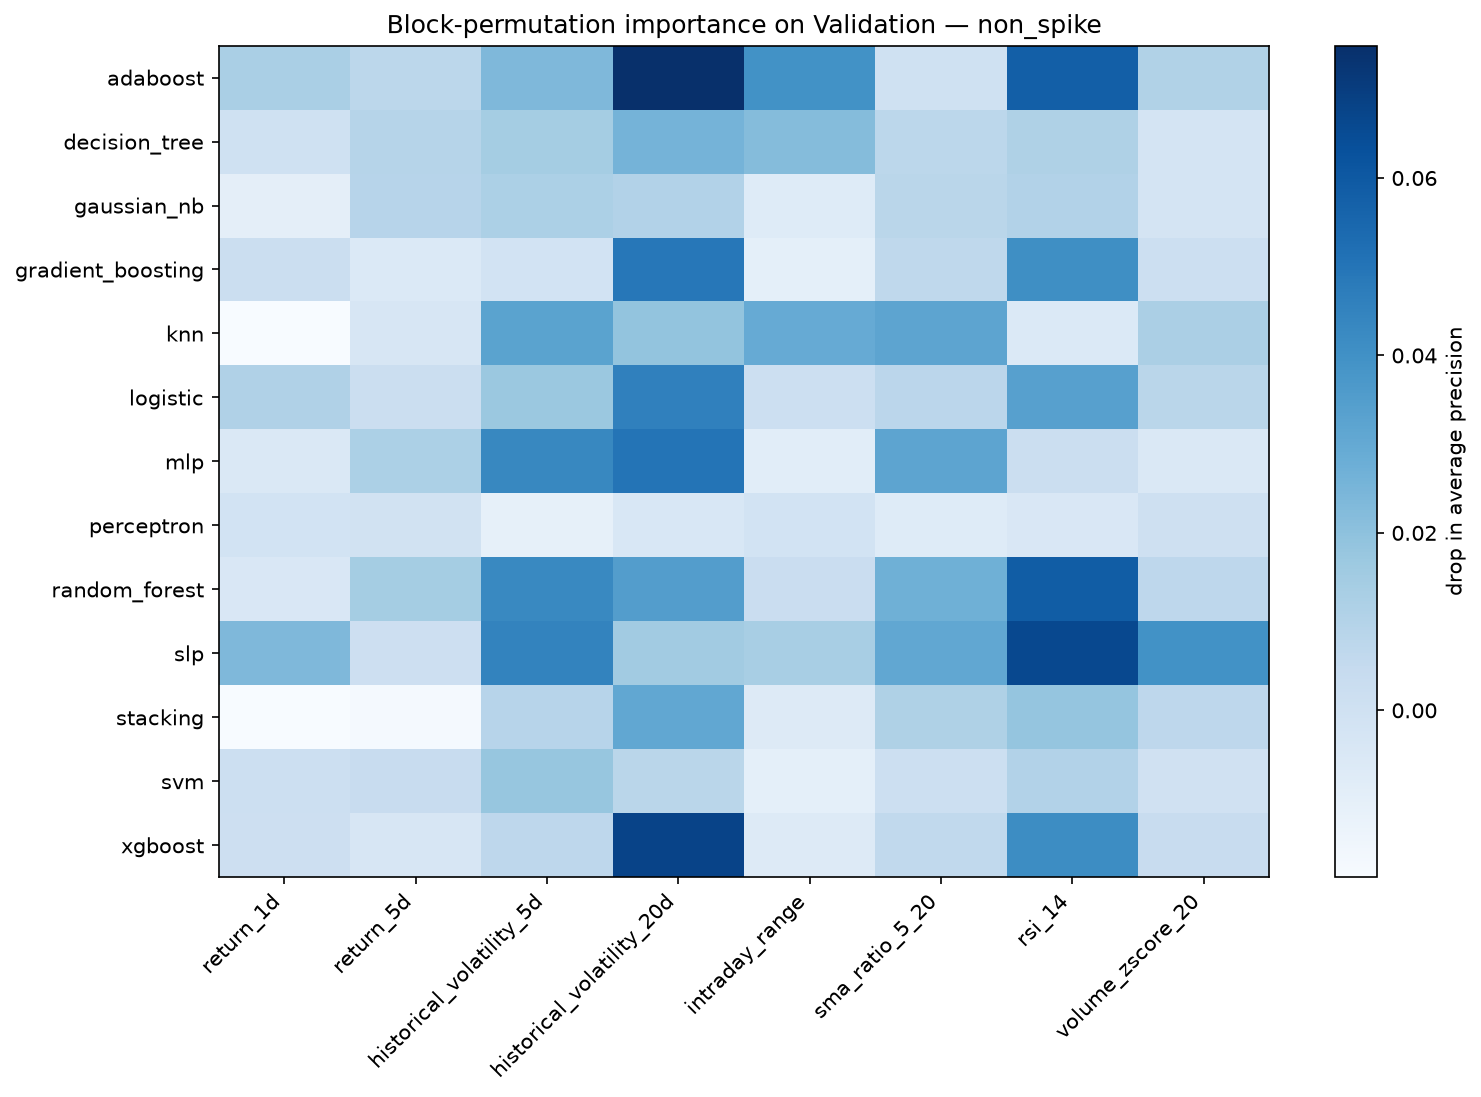

non_spike


,most important,second,third
model,,,
adaboost,historical_volatility_20d (+0.075 ± 0.062),rsi_14 (+0.058 ± 0.029),intraday_range (+0.039 ± 0.035)
decision_tree,historical_volatility_20d (+0.026 ± 0.026),intraday_range (+0.022 ± 0.013),historical_volatility_5d (+0.014 ± 0.007)
gaussian_nb,historical_volatility_5d (+0.012 ± 0.017),rsi_14 (+0.010 ± 0.016),historical_volatility_20d (+0.010 ± 0.014)
gradient_boosting,historical_volatility_20d (+0.049 ± 0.057),rsi_14 (+0.041 ± 0.027),sma_ratio_5_20 (+0.006 ± 0.019)
knn,historical_volatility_5d (+0.032 ± 0.023),sma_ratio_5_20 (+0.032 ± 0.026),intraday_range (+0.029 ± 0.024)
logistic,historical_volatility_20d (+0.046 ± 0.055),rsi_14 (+0.034 ± 0.026),historical_volatility_5d (+0.017 ± 0.017)
mlp,historical_volatility_20d (+0.050 ± 0.046),historical_volatility_5d (+0.043 ± 0.036),sma_ratio_5_20 (+0.032 ± 0.018)
perceptron,volume_zscore_20 (+0.001 ± 0.009),return_5d (-0.001 ± 0.006),return_1d (-0.001 ± 0.003)
random_forest,rsi_14 (+0.059 ± 0.028),historical_volatility_5d (+0.043 ± 0.032),historical_volatility_20d (+0.035 ± 0.028)


In [14]:
for variant in VARIANTS:
    show_image(FIGURE_ROOT / variant / "feature_importance.png", width=820)
    importance = table(REPORT_ROOT / variant / "feature_importance.csv").query("task == 'classification'")
    top = (importance.sort_values("importance_mean", ascending=False).groupby("model").head(3)
           .assign(rank=lambda frame: frame.groupby("model").cumcount() + 1,
                   value=lambda frame: frame["feature"] + " (" + frame["importance_mean"].map("{:+.3f}".format)
                   + " ± " + frame["importance_std"].map("{:.3f}".format) + ")")
           .pivot(index="model", columns="rank", values="value"))
    top.columns = ["most important", "second", "third"]
    print(variant)
    display(top)

## 14. Robustness: walk-forward ภายใน Train

Validation มีวัน positive แค่ 34 วันจากสภาพตลาดแบบเดียว เราจึงตรวจซ้ำอีกทางว่าอันดับของโมเดลคงที่ข้ามช่วงเวลาหรือไม่

**วิธีทำ:** แบ่ง Train เป็นช่วงตามเวลา เทรนด้วยข้อมูลช่วงต้น แล้วทดสอบกับช่วงถัดไป ขยายหน้าต่างไปเรื่อย ๆ 4 รอบ (เว้น purge gap ระหว่างช่วงเทรนกับช่วงทดสอบ) ใช้การตั้งค่าที่ชนะบน Validation ตัวเดิม **ไม่มีการเลือกโมเดลหรือปรับค่าใหม่** จากผลนี้

**ข้อดี:** ช่วงทดสอบรวมกันมีวัน positive หลายร้อยวัน และครอบคลุมหลายสภาพตลาดรวมถึงปี 2020

**ข้อจำกัด:** โมเดลในตารางนี้เทรนด้วยข้อมูลน้อยกว่าโมเดลจริง จึงเป็นหลักฐานเสริมเรื่องความเสถียร ไม่ใช่คะแนนของโมเดลที่ส่ง

**หมายเหตุเรื่อง `stacking`:** ช่อง fold 0 ว่าง เพราะ 275 วันแรกของ Train (ก.ย. 2016 ถึง ต.ค. 2017) ไม่มีวันผันผวนสูงเลย `stacking` ต้องแบ่งข้อมูลภายในอีกชั้นเพื่อเทรน meta-model จึงเทรนบนประวัติที่สั้นที่สุดไม่ได้ แถว pooled ของมันจึงมาจาก 3 fold และเทียบกับตัวอื่นตรง ๆ ไม่ได้

In [15]:
for variant in VARIANTS:
    walk = table(REPORT_ROOT / variant / "walk_forward.csv")
    folds = walk[walk["fold"].astype(str) != "pooled"].pivot(index="model", columns="fold", values="average_precision")
    folds.columns = [f"fold {column} AP" for column in folds.columns]
    pooled = walk[walk["fold"].astype(str) == "pooled"].set_index("model")
    summary = folds.join(pooled[["positives", "average_precision", "average_precision_low", "average_precision_high"]])
    summary = summary.rename(columns={"average_precision": "pooled AP", "average_precision_low": "pooled low",
                                      "average_precision_high": "pooled high"})
    print(variant)
    display(summary.sort_values("pooled AP", ascending=False).round(4))

with_spike


,fold 0 AP,fold 1 AP,fold 2 AP,fold 3 AP,positives,pooled AP,pooled low,pooled high
model,,,,,,,,
gaussian_nb,0.8282,0.6361,0.7775,0.4436,353,0.7124,0.5717,0.8151
gradient_boosting,0.8117,0.5722,0.8168,0.5522,353,0.7120,0.5857,0.8059
logistic,0.8173,0.6103,0.7847,0.4511,353,0.7030,0.5548,0.8083
random_forest,0.8079,0.6003,0.8018,0.5108,353,0.6833,0.5582,0.7797
svm,0.7946,0.6118,0.7839,0.4556,353,0.6718,0.5280,0.7842
slp,0.7946,0.5278,0.7658,0.4313,353,0.6717,0.5205,0.7813
adaboost,0.7998,0.5650,0.8330,0.4458,353,0.6708,0.5383,0.7772
xgboost,0.7604,0.5602,0.8042,0.5628,353,0.6690,0.5514,0.7645
mlp,0.7662,0.5310,0.8070,0.4385,353,0.6663,0.5203,0.7738


non_spike


,fold 0 AP,fold 1 AP,fold 2 AP,fold 3 AP,positives,pooled AP,pooled low,pooled high
model,,,,,,,,
stacking,NaN,0.5782,0.6482,0.4522,191,0.5666,0.4375,0.6853
gaussian_nb,0.3405,0.5518,0.6727,0.4235,211,0.5578,0.4271,0.6590
random_forest,0.3386,0.5408,0.6765,0.4222,211,0.5425,0.4098,0.6590
knn,0.3376,0.5442,0.7030,0.4203,211,0.5417,0.3957,0.6603
logistic,0.2622,0.4996,0.6770,0.4000,211,0.5399,0.4019,0.6477
xgboost,0.3175,0.5037,0.7020,0.3927,211,0.5238,0.3871,0.6469
gradient_boosting,0.3800,0.4836,0.6528,0.4287,211,0.5234,0.3883,0.6430
slp,0.3711,0.4578,0.6540,0.3513,211,0.5028,0.3635,0.6237
adaboost,0.2976,0.4025,0.6531,0.4130,211,0.5020,0.3604,0.6220


**อ่านตาราง:** ดูสองอย่าง (1) คะแนนของโมเดลเดียวกันต่างกันมากแค่ไหนระหว่าง fold ซึ่งบอกว่าสภาพตลาดมีผลมากกว่าชนิดของโมเดลหรือไม่ และ (2) ช่วง `pooled low` ถึง `pooled high` ของแต่ละโมเดลซ้อนทับกันหรือไม่ notebook 05 นำอันดับนี้ไปเทียบกับอันดับบน Validation

## 15. สรุป

**ข้อค้นพบ**

1. บน Validation classifier ส่วนใหญ่ได้ AP ราว 0.20 ถึง 0.30 สูงกว่าการเดาสุ่ม (0.092) แต่ช่วงความเชื่อมั่นกว้างจนแยกอันดับระหว่างโมเดลไม่ได้
2. `baseline_persistence` ซึ่งไม่ได้เทรนอะไรเลย ทำได้ใกล้เคียงโมเดลส่วนใหญ่ และมี ROC-AUC สูงสุด ข้อมูลที่ใช้ทำนายได้จึงมาจากความผันผวนย้อนหลังเป็นหลัก
3. โมเดลส่วนใหญ่ทำนาย positive น้อยเกินไป (recall 0.15 ถึง 0.32) ที่ threshold 0.5 เพราะ Validation สงบกว่า Train

**ข้อจำกัด**

- วัน positive 34 วันน้อยเกินกว่าจะตัดสินผู้ชนะ และตัวเลขทั้งหมดเป็น selection score
- ผลบน Test ที่อ่านครั้งเดียวอยู่ใน `05_results_comparison.ipynb`

In [16]:
import matplotlib

provenance = []
for variant in VARIANTS:
    for run in read_runs(OUTPUT_ROOT, variant, task=TASK):
        provenance.append({"variant": variant, "model": run.name,
                           "train_sha256": run.config["train_sha256"][:16],
                           "validation_sha256": run.config["validation_sha256"][:16]})
display(pd.DataFrame(provenance))
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__)

,variant,model,train_sha256,validation_sha256
0,with_spike,adaboost,424f1bda5c4211ac,b84a5fa31fe1afc6
1,with_spike,decision_tree,424f1bda5c4211ac,b84a5fa31fe1afc6
2,with_spike,gaussian_nb,424f1bda5c4211ac,b84a5fa31fe1afc6
3,with_spike,gradient_boosting,424f1bda5c4211ac,b84a5fa31fe1afc6
4,with_spike,knn,424f1bda5c4211ac,b84a5fa31fe1afc6
5,with_spike,logistic,424f1bda5c4211ac,b84a5fa31fe1afc6
6,with_spike,mlp,424f1bda5c4211ac,b84a5fa31fe1afc6
7,with_spike,perceptron,424f1bda5c4211ac,b84a5fa31fe1afc6
8,with_spike,random_forest,424f1bda5c4211ac,b84a5fa31fe1afc6
9,with_spike,slp,424f1bda5c4211ac,b84a5fa31fe1afc6


Python 3.14.8 | NumPy 2.5.3 | pandas 3.0.6 | matplotlib 3.11.2
